# Event-SNN vs RGB-ANN embedded object detection — trained-SNN + SANA-FE study (v1.0.9)

This notebook starts from a **blank Colab runtime** and reconstructs the complete standalone project. It does **not clone or patch Cordone's model repository**.

For each ST-VGG / ResCat width (16, 32, 64), we compare:

- **A — Event-SNN:** `Padding → BN(input) → Conv → PLIF`
- **B — Strict RGB-ANN twin:** `Padding → BN(input) → Conv → ReLU`
- **C — ANN-native RGB:** `Conv → BN(output) → ReLU`

The six Event-SNNs are lightly trained on the same small labeled DSEC fragment only to move them away from random-weight activity. **No target spike rate is forced, no dead-layer rescue is applied, and dead/near-dead/saturated layers are only reported.**

v1.0.9 keeps the v1.0.5 benchmark philosophy but makes three corrections:
1. fixes the per-layer `min / median / max` spike-rate summary bug;
2. makes every SANA-FE output explicitly labeled as a **layer-aggregated Loihi-1-like spiking-subgraph projection**, not an exact mapping or hardware measurement;
3. reduces the limited-fragment training default to **5 epochs** so training is not prolonged merely to manipulate spike activity.

The final study keeps Chapter-6 analytical energy, robust NVIDIA NVML measurements, and **SANA-FE as the only external neuromorphic-hardware simulator**.


## 0. GPU/runtime check

In [1]:
import sys, platform, torch
print('Python:', sys.version)
print('Platform:', platform.platform())
print('Torch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: benchmark will run on CPU. Enable a GPU runtime for latency/VRAM/NVML energy.')


Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.35
Torch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 1. Install dependencies

In [2]:
import sys, subprocess, importlib.metadata as md

# Keep Colab's modern NumPy stack intact. On Python >=3.13, NumPy 2.x is required by
# much of the preinstalled scientific stack and NumPy 1.26 does not support Python 3.13.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "hdf5plugin", "nvidia-ml-py", "pandas", "tabulate",
    "pycocotools", "torchmetrics", "pytest", "jedi"
])

import numpy as np
print("Core dependencies installed")
print("NumPy runtime:", np.__version__)
print("NumPy metadata:", md.version("numpy"))
if sys.version_info >= (3, 13):
    major = int(np.__version__.split('.')[0])
    assert major >= 2, (
        "Python 3.13 Colab should stay on NumPy 2.x. "
        "Keep the runtime NumPy major version compatible with Colab."
    )


Core dependencies installed
NumPy runtime: 2.1.3
NumPy metadata: 2.1.3


## 2. Reconstruct the final standalone source tree

The ZIP is embedded in this notebook. No separate source upload and no upstream model clone are required.


In [3]:
PROJECT_ZIP_B64 = (
    '...'
)

import base64, zipfile, io, shutil
from pathlib import Path

PROJECT_ROOT = Path('/content/event_frame_embedded_od')
if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)

payload = base64.b64decode(PROJECT_ZIP_B64)
with zipfile.ZipFile(io.BytesIO(payload)) as zf:
    zf.extractall('/content')

assert (PROJECT_ROOT / 'src' / 'efod' / '__init__.py').exists()
print('Reconstructed:', PROJECT_ROOT)


Reconstructed: /content/event_frame_embedded_od


In [4]:
from pathlib import Path
import sys, subprocess, importlib
PROJECT_ROOT = Path("/content/event_frame_embedded_od").resolve()
SRC_ROOT = PROJECT_ROOT / "src"
assert (SRC_ROOT / "efod" / "__init__.py").exists(), SRC_ROOT
subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", str(PROJECT_ROOT), "--no-deps"])
if str(SRC_ROOT) not in sys.path: sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()
import efod
print("EFOD import OK:", efod.__file__)


EFOD import OK: /content/event_frame_embedded_od/src/efod/__init__.py


## 3. Release validation — all 18 architectures

In [5]:
%cd /content/event_frame_embedded_od
!pytest -q
!python scripts/validate_release.py > /content/efod_release_validation.txt
print(open('/content/efod_release_validation.txt').read().splitlines()[-1])


/content/event_frame_embedded_od
............                                                             [100%]
12 passed in 8.79s
PASS: all 18 models construct; A/B/C feature interfaces match; Event-SNN core counts match thesis reconstruction.


### What is regression-tested

The event-SNN core parameter counts are checked against the thesis scale:

| Core | standalone count | thesis rounded |
|---|---:|---:|
| 16-ST-VGG | 125,484 | 125k |
| 32-ST-VGG | 499,788 | 499k |
| 64-ST-VGG | 1,994,892 | 1.994M |
| ResCat-SNN-16 | 216,399 | 216k |
| ResCat-SNN-32 | 862,351 | 862k |
| ResCat-SNN-64 | 3,442,959 | 3.442M |

The tests also verify A/B/C feature-map parity, the presence/absence of PLIF neurons, ResCat `C→2C→3C→6C→6C` progression, detector training forwards, and the analytical energy path.


## 4. Inspect the actual A/B/C architectures

In [6]:
from efod import build_model, MODEL_SPECS, PIPELINES, PIPELINE_DISPLAY
from efod.models import count_spiking_neurons
import pandas as pd, torch
rows=[]
for variant in MODEL_SPECS:
    for pipeline in PIPELINES:
        m=build_model(variant,pipeline).eval()
        rows.append({'variant':variant,'model':MODEL_SPECS[variant]['display'],'pipeline':pipeline,
                     'block':PIPELINE_DISPLAY[pipeline],
                     'core_params':sum(p.numel() for p in m.backbone.core.parameters()),
                     'total_params':m.count_parameters(),'PLIF_modules':count_spiking_neurons(m),
                     'input_channels':m.cfg.input_channels,'feature_channels':str(m.backbone.out_channels)})
arch_df=pd.DataFrame(rows)
display(arch_df)


,variant,model,pipeline,block,core_params,total_params,PLIF_modules,input_channels,feature_channels
0,vgg16,16-ST-VGG,event_snn,A Event-SNN (BN-Conv-PLIF),125484,1089815,11,2,"[32, 64, 64, 256, 128, 128]"
1,vgg16,16-ST-VGG,strict_ann,B Strict RGB-ANN twin (BN-Conv-ReLU),125734,1090062,0,3,"[32, 64, 64, 256, 128, 128]"
2,vgg16,16-ST-VGG,native_ann,C ANN-native RGB (Conv-BN-ReLU),125856,1090312,0,3,"[32, 64, 64, 256, 128, 128]"
3,vgg32,32-ST-VGG,event_snn,A Event-SNN (BN-Conv-PLIF),499788,1708471,11,2,"[64, 128, 128, 256, 128, 128]"
4,vgg32,32-ST-VGG,strict_ann,B Strict RGB-ANN twin (BN-Conv-ReLU),500294,1708974,0,3,"[64, 128, 128, 256, 128, 128]"
5,vgg32,32-ST-VGG,native_ann,C ANN-native RGB (Conv-BN-ReLU),500544,1709224,0,3,"[64, 128, 128, 256, 128, 128]"
6,vgg64,64-ST-VGG,event_snn,A Event-SNN (BN-Conv-PLIF),1994892,3692279,11,2,"[128, 256, 256, 256, 128, 128]"
7,vgg64,64-ST-VGG,strict_ann,B Strict RGB-ANN twin (BN-Conv-ReLU),1995910,3693294,0,3,"[128, 256, 256, 256, 128, 128]"
8,vgg64,64-ST-VGG,native_ann,C ANN-native RGB (Conv-BN-ReLU),1996416,3693544,0,3,"[128, 256, 256, 256, 128, 128]"
9,rescat16,ResCat-SNN-16,event_snn,A Event-SNN (BN-Conv-PLIF),216399,1302906,14,2,"[48, 96, 96, 256, 128, 128]"


In [7]:
SHOW_VARIANT='rescat32'
SHOW_PIPELINE='event_snn'  # event_snn | strict_ann | native_ann
m=build_model(SHOW_VARIANT,SHOW_PIPELINE).eval()
print(m)


DetectionSystem(
  (backbone): SSDFeatureBackbone(
    (core): ResCatBackbone(
      (patchify): PreActSpikingBlock(
        (pad): Identity()
        (bn): BatchNorm2d(2, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv): Conv2d(2, 32, kernel_size=(4, 4), stride=(4, 4), bias=False)
        (act): ParametricLIF()
      )
      (pre): PreActSpikingBlock(
        (pad): ConstantPad2d(padding=(1, 1, 1, 1), value=0.0)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
        (act): ParametricLIF()
      )
      (stage1): ResCatStage(
        (main1): PreActSpikingBlock(
          (pad): ConstantPad2d(padding=(1, 1, 1, 1), value=0.0)
          (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
          (act): ParametricLIF()
   

## 5. Download a small real DSEC fragment

We clone **DAGR only as a convenient source of its public DSEC fragment/download script**. The model implementation above remains fully standalone.


In [8]:
%cd /content
!rm -rf dagr
!git clone -q https://github.com/uzh-rpg/dagr.git
%cd /content/dagr
!bash download_example_data.sh
SEQ='/content/dagr/data/DSEC_fragment/test/zurich_city_13_b'
from pathlib import Path
assert Path(SEQ,'events/left/events.h5').exists()
assert Path(SEQ,'images/timestamps.txt').exists()
print('DSEC fragment ready:',SEQ)


/content
/content/dagr
--2026-08-31 11:03:46--  https://download.ifi.uzh.ch/rpg/dagr/data/dagr_s_50.pth
Resolving download.ifi.uzh.ch (download.ifi.uzh.ch)... 130.60.155.11
Connecting to download.ifi.uzh.ch (download.ifi.uzh.ch)|130.60.155.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 331822447 (316M)
Saving to: ‘/content/dagr/data/dagr_s_50.pth’

/content/dagr/data/ 100%[===================>] 316.45M  13.2MB/s    in 25s     

2026-08-31 11:04:12 (12.5 MB/s) - ‘/content/dagr/data/dagr_s_50.pth’ saved [331822447/331822447]

--2026-08-31 11:04:12--  https://download.ifi.uzh.ch/rpg/dagr/data/DSEC_fragment.zip
Resolving download.ifi.uzh.ch (download.ifi.uzh.ch)... 130.60.155.11
Connecting to download.ifi.uzh.ch (download.ifi.uzh.ch)|130.60.155.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 79677115 (76M) [application/zip]
Saving to: ‘/content/dagr/data/DSEC_fragment.zip’

/content/dagr/data/ 100%[===================>]  75.99M  19

## 6. Data sanity: aligned RGB/event/target sample

In [9]:
from pathlib import Path
import numpy as np, hdf5plugin, h5py
hdf5plugin.register(force=True)
print("hdf5plugin:", getattr(hdf5plugin, "__version__", "installed"))
print("Blosc filter available:", bool(h5py.h5z.filter_avail(32001)))
from efod.data.dsec import load_event_window, load_rgb_frame, tracks_to_target
seq=Path(SEQ)
ts=np.atleast_1d(np.loadtxt(seq/"images/timestamps.txt",dtype=np.int64))
imgs=sorted((seq/"images/left/distorted").glob("*.png"))
tracks=np.load(seq/"object_detections/left/tracks.npy")
i=min(1,len(ts)-1)
event=load_event_window(seq/"events/left/events.h5",int(ts[i]),direction="past")
frame=load_rgb_frame(imgs[i])
target=tracks_to_target(tracks,int(ts[i]),640,480)
print("timestamp:",int(ts[i]))
print("event:",tuple(event.shape),"occupancy=",float((event!=0).float().mean()))
print("frame:",tuple(frame.shape),frame.min().item(),frame.max().item())
print("target boxes:",target["boxes"].shape,"labels:",target["labels"].tolist())


hdf5plugin: installed
Blosc filter available: True
timestamp: 41675450191
event: (2, 480, 640) occupancy= 0.23173339664936066
frame: (3, 480, 640) 0.0 1.0
target boxes: torch.Size([10, 4]) labels: [0, 0, 0, 0, 2, 2, 2, 2, 2, 2]


## 7. Lightly train the six Event-SNNs on the available DAGr/DSEC fragment

Before the unified benchmark, lightly train the six Event-SNNs on the available labeled fragment so the SNN rows use learned rather than random spike activity. It deliberately uses **all available labeled windows** of `zurich_city_13_b` for training because the goal is computational/hardware characterization rather than held-out DSEC accuracy.

Training is chronological and preserves membrane state between 50-ms windows. A **fixed 5-epoch budget** is used by default. There is no validation/best-epoch selection, no train-until-healthy logic, no target spike rate, and no post-training activity rescue.

The optimizer settings remain the same limited-fragment setup used previously: Adam, `lr=5e-3`, `weight_decay=1e-2`, cosine annealing, PLIF `tau=2`, threshold `1`, ATan surrogate, and gradient clipping at norm `1`.

**Activity is an observed result, not a training objective.** Cordone's GEN1 detector activities are shown later only as context; DSEC need not reproduce them.

To respect the storage constraint, checkpoints contain the model state needed for the benchmark rather than large optimizer-state archives.


In [10]:
from pathlib import Path
import pandas as pd, torch

TRAIN_VARIANTS = ['vgg16','vgg32','vgg64','rescat16','rescat32','rescat64']
TRAIN_EPOCHS = 5                 # intentionally light limited-fragment training
PROBE_WINDOWS = 24
FRAGMENT_CKPT_DIR = Path('/content/fragment_checkpoints')

print('Training sequence:', SEQ)
print('Variants:', TRAIN_VARIANTS)
print('Epochs:', TRAIN_EPOCHS)
print('Policy: fixed epoch budget; no adaptive rescue and no spike-rate target.')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')


Training sequence: /content/dagr/data/DSEC_fragment/test/zurich_city_13_b
Variants: ['vgg16', 'vgg32', 'vgg64', 'rescat16', 'rescat32', 'rescat64']
Epochs: 5
Policy: fixed epoch budget; no adaptive rescue and no spike-rate target.
GPU: Tesla T4


In [20]:
%cd /content/event_frame_embedded_od
import subprocess, sys

cmd = [
    sys.executable, 'scripts/train_fragment_snn_matrix.py',
    '--sequence-dir', SEQ,
    '--variants', *TRAIN_VARIANTS,
    '--epochs', str(TRAIN_EPOCHS),
    '--probe-windows', str(PROBE_WINDOWS),
    '--lr', '5e-3',
    '--weight-decay', '1e-2',
    '--grad-clip', '1.0',
    '--max-unlabeled-steps', '5',
    '--workers', '0',
    '--outdir', str(FRAGMENT_CKPT_DIR),
]
print(' '.join(cmd))
subprocess.run(cmd, check=True)


/content/event_frame_embedded_od
/usr/bin/python3 scripts/train_fragment_snn_matrix.py --sequence-dir /content/dagr/data/DSEC_fragment/test/zurich_city_13_b --variants vgg16 vgg32 vgg64 rescat16 rescat32 rescat64 --epochs 5 --probe-windows 24 --lr 5e-3 --weight-decay 1e-2 --grad-clip 1.0 --max-unlabeled-steps 5 --workers 0 --outdir /content/fragment_checkpoints


CompletedProcess(args=['/usr/bin/python3', 'scripts/train_fragment_snn_matrix.py', '--sequence-dir', '/content/dagr/data/DSEC_fragment/test/zurich_city_13_b', '--variants', 'vgg16', 'vgg32', 'vgg64', 'rescat16', 'rescat32', 'rescat64', '--epochs', '5', '--probe-windows', '24', '--lr', '5e-3', '--weight-decay', '1e-2', '--grad-clip', '1.0', '--max-unlabeled-steps', '5', '--workers', '0', '--outdir', '/content/fragment_checkpoints'], returncode=0)

### Inspect the training trajectory

The probe activity is measured in `eval()` mode on a short chronological segment after every epoch. It is **not an accuracy metric**; it lets us see whether BN running statistics and learned SNN weights have moved the model out of the nearly silent random-initialization regime.

In [21]:
hist = pd.read_csv(FRAGMENT_CKPT_DIR/'training_history.csv')
display(hist[['variant','epoch','loss','bbox_regression_loss','classification_loss','updates','probe_spike_rate_pct','lr']])

final_hist = hist.sort_values('epoch').groupby('variant',as_index=False).tail(1)
print('Final-epoch activity probes:')
display(final_hist[['variant','loss','probe_spike_rate_pct','updates']].sort_values('variant'))


,variant,epoch,loss,bbox_regression_loss,classification_loss,updates,probe_spike_rate_pct,lr
0,vgg16,0,359.029132,3.136561,355.892569,40,24.282165,0.004523
1,vgg16,1,5.722353,3.413931,2.308421,40,23.712626,0.003273
2,vgg16,2,5.671591,3.420510,2.251082,40,17.792524,0.001727
3,vgg16,3,4.593497,2.985994,1.607503,40,14.115975,0.000477
4,vgg16,4,6.080373,2.470782,3.609591,40,16.381830,0.000000
5,vgg32,0,215.015774,3.182339,211.833434,40,23.129987,0.004523
6,vgg32,1,6.793805,3.622885,3.170920,40,16.294918,0.003273
7,vgg32,2,5.756733,3.195005,2.561727,40,15.698376,0.001727
8,vgg32,3,55.435991,4.097129,51.338862,40,23.781907,0.000477
9,vgg32,4,9.594561,2.631749,6.962812,40,21.506753,0.000000


Final-epoch activity probes:


,variant,loss,probe_spike_rate_pct,updates
19,rescat16,3.945973,20.737989,40
24,rescat32,4.425526,18.126597,40
29,rescat64,13.588746,13.691037,40
4,vgg16,6.080373,16.381830,40
9,vgg32,9.594561,21.506753,40
14,vgg64,12.554022,12.090724,40


### Activity reference before benchmarking

Cordone's trained GEN1 object detectors reported global activity in the **tens of percent**. These values are only a reference: DSEC is a different sensor/workload and we do **not** tune the model to reproduce them. The purpose of the training above is simply to avoid the near-dead random-weight regime.

In [22]:
GEN1_ACTIVITY_REF_PCT = {
    'vgg16': 37.66,
    'vgg32': 36.24,
    'vgg64': 38.87,
    'rescat16': 33.71,
    'rescat32': 35.59,
    'rescat64': 45.14,
}
probe_compare = final_hist[['variant','probe_spike_rate_pct']].copy()
probe_compare['GEN1_published_activity_pct'] = probe_compare['variant'].map(GEN1_ACTIVITY_REF_PCT)
display(probe_compare.sort_values('variant'))

if (probe_compare['probe_spike_rate_pct'] < 0.1).any():
    print('WARNING: at least one SNN is still almost silent (<0.1%). This is reported as an observed limitation; do not automatically extend training just to force a higher spike rate.')
else:
    print('Training probe: all six SNNs moved out of the near-zero random-weight activity regime.')
print('GEN1 values are contextual references only and are not targets.')


,variant,probe_spike_rate_pct,GEN1_published_activity_pct
19,rescat16,20.737989,33.71
24,rescat32,18.126597,35.59
29,rescat64,13.691037,45.14
4,vgg16,16.381830,37.66
9,vgg32,21.506753,36.24
14,vgg64,12.090724,38.87


Training probe: all six SNNs moved out of the near-zero random-weight activity regime.
GEN1 values are contextual references only and are not targets.


## 8. Unified final 18-model benchmark — **trained Event-SNNs**

This is the single benchmark used for the comparison. The six `event_snn` rows load the checkpoints produced above; they are **not random SNNs**. The strict/native RGB-ANN twins remain structural dense baselines unless you separately provide ANN checkpoints.

The benchmark measures parameters/model memory, dense MAC/FLOP proxy, streaming/reset latency and FPS, P95, peak CUDA VRAM, membrane state, **learned SNN activity/sparsity**, Chapter-6 analytical energy, per-layer spike-health diagnostics, and the robust NVIDIA GPU-energy measurements. The SANA-FE projection is run afterward from these measured activity files.

For GPU energy, v1.0.5 uses the robust protocol we agreed on: **3 warm-up traversals → 5 repeated active runs → 10 s active per repeat → continuous NVML polling → idle before and after each repeat → baseline from the two idle medians → mean/SD/Student-t 95% CI**. A dynamic-energy run that does not rise above its idle baseline is marked invalid instead of being clipped to a fake zero. Per-repeat measurements are saved under `efod_results/gpu_energy/`.

The SNN pass also aggregates **every PLIF layer** over the complete chronological workload and flags dead/near-dead/saturated layers. Event-input occupancy is recorded so firing activity can be interpreted against the actual event sparsity.

`--require-trained-snn` makes the run fail rather than silently falling back to random SNN weights. `WINDOWS=0` means use **all available causal windows** in the DAGr fragment.

In [23]:
%cd /content/event_frame_embedded_od
RUN_GPU_ENERGY=True
WINDOWS=0  # <=0 = every available causal 50-ms window in the fragment
GPU_ENERGY_REPEATS=5
GPU_ACTIVE_SECONDS=10
GPU_IDLE_SECONDS=2
GPU_POLL_SECONDS=0.02

cmd=[
    sys.executable,'scripts/benchmark.py',
    '--sequence-dir',SEQ,
    '--windows',str(WINDOWS),
    '--checkpoint-dir',str(FRAGMENT_CKPT_DIR),
    '--require-trained-snn',
    '--outdir','/content/efod_results',
]
if RUN_GPU_ENERGY and torch.cuda.is_available():
    cmd += [
        '--gpu-energy',
        '--gpu-energy-repeats',str(GPU_ENERGY_REPEATS),
        '--gpu-energy-duration',str(GPU_ACTIVE_SECONDS),
        '--gpu-idle-duration',str(GPU_IDLE_SECONDS),
        '--gpu-poll-interval',str(GPU_POLL_SECONDS),
    ]
print('This final energy protocol can take roughly 20–30 minutes for all 18 models on Colab.')
print(' '.join(cmd))
import subprocess
subprocess.run(cmd,check=True)

/content/event_frame_embedded_od
This final energy protocol can take roughly 20–30 minutes for all 18 models on Colab.
/usr/bin/python3 scripts/benchmark.py --sequence-dir /content/dagr/data/DSEC_fragment/test/zurich_city_13_b --windows 0 --checkpoint-dir /content/fragment_checkpoints --require-trained-snn --outdir /content/efod_results --gpu-energy --gpu-energy-repeats 5 --gpu-energy-duration 10 --gpu-idle-duration 2 --gpu-poll-interval 0.02


CompletedProcess(args=['/usr/bin/python3', 'scripts/benchmark.py', '--sequence-dir', '/content/dagr/data/DSEC_fragment/test/zurich_city_13_b', '--windows', '0', '--checkpoint-dir', '/content/fragment_checkpoints', '--require-trained-snn', '--outdir', '/content/efod_results', '--gpu-energy', '--gpu-energy-repeats', '5', '--gpu-energy-duration', '10', '--gpu-idle-duration', '2', '--gpu-poll-interval', '0.02'], returncode=0)

## 9. Main comparison table

In [24]:
df=pd.read_csv('/content/efod_results/benchmark_18_models.csv')
cols=[c for c in [
    'model','pipeline','weights_state','params','state_dict_mib','fp32_param_mib','snn_state_mib',
    'dense_gmacs','dense_gflops_2xmac','effective_macs_ch6','effective_accs_ch6',
    'event_input_occupancy_mean','seq_spike_rate','seq_spike_sparsity',
    'seq_spike_layer_rate_min','seq_spike_layer_rate_median','seq_spike_layer_rate_max',
    'seq_spike_dead_la yers','seq_spike_near_dead_layers','seq_spike_saturated_layers','seq_spike_health_status',
    'seq_latency_stream_mean_ms','seq_latency_stream_p95_ms','seq_latency_stream_fps','peak_vram_mib',
    'thesis_memory_uJ','thesis_synaptic_uJ','thesis_address_uJ','thesis_total_uJ',
    'gpu_seq_energy_status','gpu_seq_power_idle_w','gpu_seq_power_active_w','gpu_seq_power_dynamic_w',
    'gpu_seq_energy_dynamic_mj','gpu_seq_energy_dynamic_std_mj',
    'gpu_seq_energy_dynamic_ci95_low_mj','gpu_seq_energy_dynamic_ci95_high_mj',
    'gpu_seq_energy_repeats_valid','gpu_seq_energy_repeats_requested',
] if c in df.columns]
display(df[cols])
print('CSV: /content/efod_results/benchmark_18_models.csv')


,model,pipeline,weights_state,params,state_dict_mib,fp32_param_mib,snn_state_mib,dense_gmacs,dense_gflops_2xmac,effective_macs_ch6,...,gpu_seq_energy_status,gpu_seq_power_idle_w,gpu_seq_power_active_w,gpu_seq_power_dynamic_w,gpu_seq_energy_dynamic_mj,gpu_seq_energy_dynamic_std_mj,gpu_seq_energy_dynamic_ci95_low_mj,gpu_seq_energy_dynamic_ci95_high_mj,gpu_seq_energy_repeats_valid,gpu_seq_energy_repeats_requested
0,16-ST-VGG,event_snn,trained_limited_fragment,1089815,4.197560,4.157314,7.781250,0.602991,1.205981,1.453117e+08,...,ok,33.39905,40.907475,7.508425,73.724565,5.074669,67.424541,80.024589,5,5
1,16-ST-VGG,strict_ann,random_untrained,1090062,4.195394,4.158257,0.000000,0.607906,1.215812,6.079058e+08,...,ok,34.35410,46.223035,11.868935,73.840985,1.744848,71.674817,76.007153,5,5
2,16-ST-VGG,native_ann,random_untrained,1090312,4.197103,4.159210,0.000000,0.607906,1.215812,6.079058e+08,...,ok,34.55620,45.060030,10.503830,58.244860,3.028884,54.484607,62.005114,5,5
3,32-ST-VGG,event_snn,trained_limited_fragment,1708471,6.560109,6.517300,15.471680,2.047107,4.094214,2.758909e+08,...,ok,39.54750,61.283020,21.735520,238.190011,39.050352,189.710367,286.669654,5,5
4,32-ST-VGG,strict_ann,random_untrained,1708974,6.558919,6.519218,0.000000,2.056937,4.113875,2.056937e+09,...,ok,38.37730,62.932664,24.555364,168.577536,20.807133,142.746210,194.408862,5,5
5,32-ST-VGG,native_ann,random_untrained,1709224,6.560628,6.520172,0.000000,2.056937,4.113875,2.056937e+09,...,ok,39.48010,62.906284,23.426184,143.258854,26.154188,110.789346,175.728362,5,5
6,64-ST-VGG,event_snn,trained_limited_fragment,3692279,14.132924,14.084927,30.852539,7.523193,15.046386,5.370493e+08,...,ok,40.45150,65.728924,25.277424,376.355852,38.953995,327.995833,424.715871,5,5
7,64-ST-VGG,strict_ann,random_untrained,3693294,14.133626,14.088799,0.000000,7.542854,15.085707,7.542854e+09,...,ok,40.15000,65.733997,25.583997,244.986844,29.524431,208.333298,281.640390,5,5
8,64-ST-VGG,native_ann,random_untrained,3693544,14.135335,14.089752,0.000000,7.542854,15.085707,7.542854e+09,...,ok,40.48650,65.551748,25.065248,213.500039,24.330849,183.294143,243.705936,5,5
9,ResCat-SNN-16,event_snn,trained_limited_fragment,1302906,5.020396,4.970192,8.696777,0.805574,1.611147,2.098333e+08,...,ok,33.79140,41.223018,7.431618,89.453946,4.065807,84.406389,94.501503,5,5


CSV: /content/efod_results/benchmark_18_models.csv


## 10. A/B/C paired ratios

In [25]:
pairs=pd.read_csv('/content/efod_results/paired_ABC_ratios.csv')
display(pairs)


,variant,params_A_over_B,params_A_over_C,dense_macs_A_over_B,dense_macs_A_over_C,effective_macs_A_over_B,effective_accs_A_over_B,latency_stream_A_over_B,latency_stream_A_over_C,thesis_energy_A_over_B,thesis_energy_A_over_C,gpu_dynamic_energy_A_over_B,gpu_dynamic_energy_A_over_C
0,vgg16,0.999773,0.999544,0.991915,0.991915,0.239037,40.201198,1.600953,1.815540,0.661012,0.665148,0.998423,1.265769
1,vgg32,0.999706,0.999559,0.995221,0.995221,0.134127,88.704619,1.964660,2.240982,0.671082,0.674578,1.412940,1.662655
2,vgg64,0.999725,0.999658,0.997393,0.997393,0.071200,117.766291,1.567756,1.604141,0.447825,0.447934,1.536229,1.762791
3,rescat16,0.999813,0.999891,0.993936,0.993936,0.258897,61.340682,1.647336,1.777369,0.702643,0.711529,1.060263,1.273717
4,rescat32,0.999784,0.999980,0.996395,0.996395,0.148496,118.734338,1.648674,1.836433,0.565018,0.571127,1.525633,1.705453
5,rescat64,0.999820,1.000026,0.998022,0.998022,0.079977,180.040009,1.534286,1.662829,0.427454,0.427615,1.508371,1.644989


## 11. Plot computation comparisons

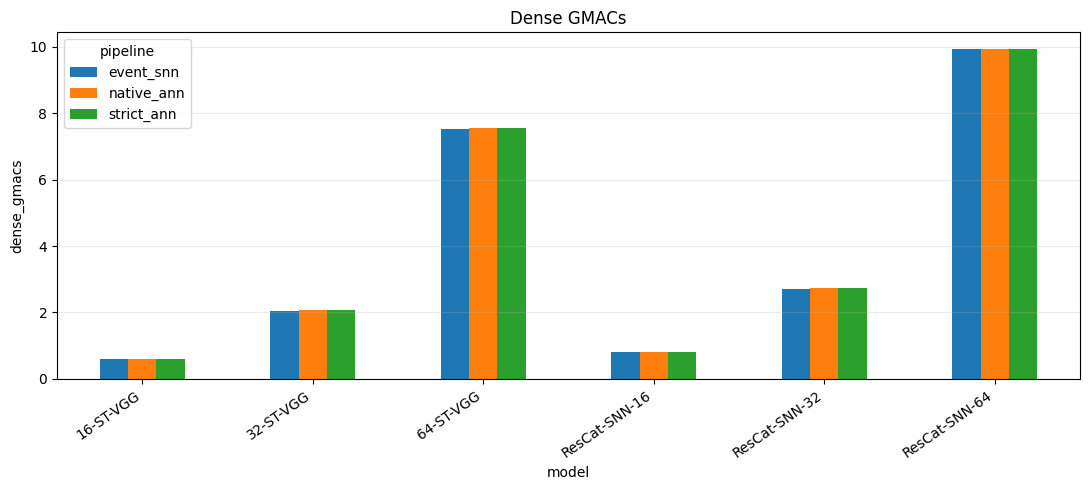

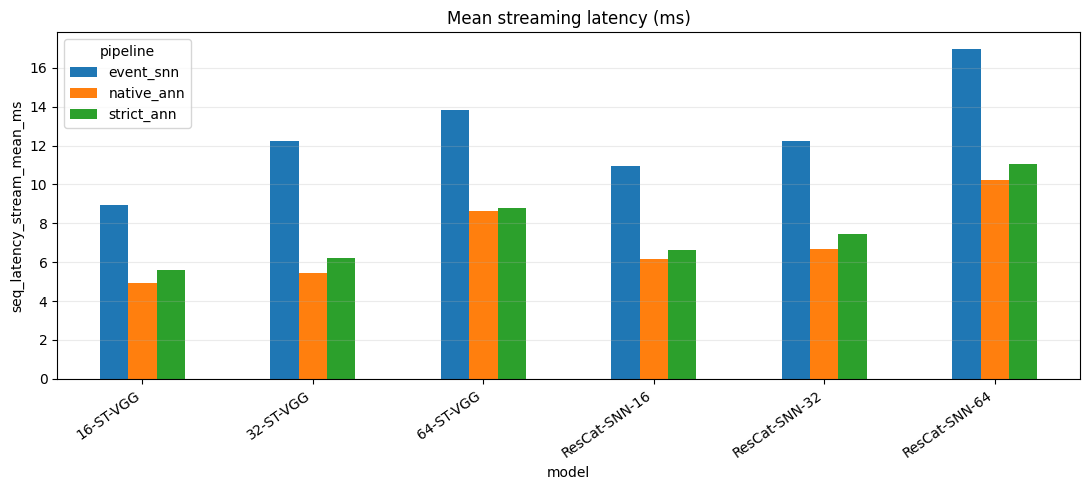

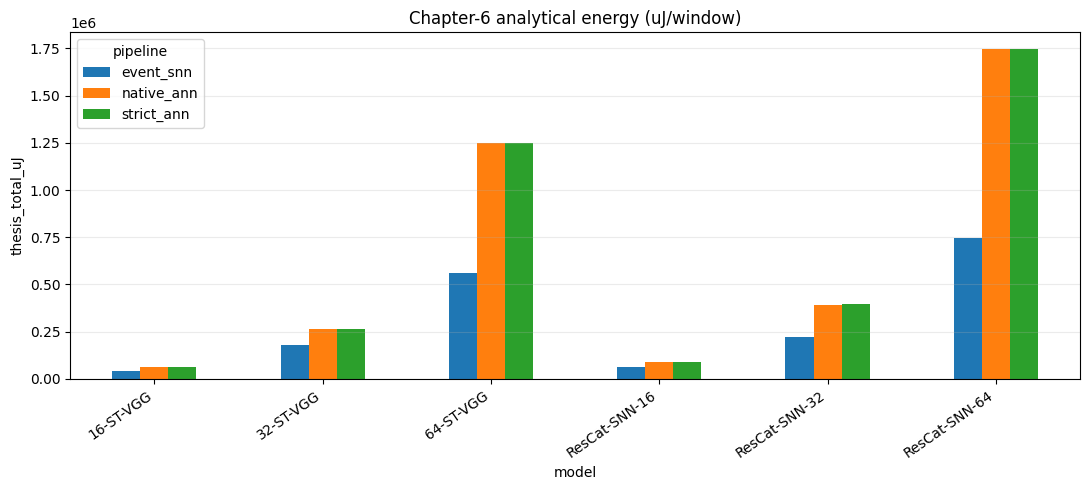

In [26]:
import matplotlib.pyplot as plt
for metric,title in [('dense_gmacs','Dense GMACs'),('seq_latency_stream_mean_ms','Mean streaming latency (ms)'),('thesis_total_uJ','Chapter-6 analytical energy (uJ/window)')]:
    if metric not in df: continue
    pivot=df.pivot(index='model',columns='pipeline',values=metric)
    ax=pivot.plot(kind='bar',figsize=(11,5))
    ax.set_title(title); ax.set_ylabel(metric); ax.grid(axis='y',alpha=.25)
    plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.show()


## 12. Per-layer energy/activity details

In [27]:
SELECT_VARIANT='rescat32'; SELECT_PIPELINE='event_snn'
energy_path=Path('/content/efod_results/layer_energy')/f'{SELECT_VARIANT}_{SELECT_PIPELINE}.csv'
activity_path=Path('/content/efod_results/spike_activity')/f'{SELECT_VARIANT}_{SELECT_PIPELINE}.csv'
activity_summary_path=Path('/content/efod_results/spike_activity_summary')/f'{SELECT_VARIANT}_{SELECT_PIPELINE}.csv'
print('Energy rows:'); display(pd.read_csv(energy_path).head(50))
if activity_path.exists():
    print('Per-window spike rows:'); display(pd.read_csv(activity_path).head(50))
if activity_summary_path.exists():
    print('Whole-workload per-layer spike summary:')
    layer_df=pd.read_csv(activity_summary_path)
    display(layer_df[['name','rate_pct','window_rate_min','window_rate_max','dead','near_dead','saturated']])


Energy rows:


,window,name,kind,dense_macs,synaptic_macs,synaptic_accs,address_macs,address_accs,theta_in,theta_out,in_reads,parameter_reads,potential_reads,output_writes,potential_writes,memory_energy_pj,synaptic_energy_pj,address_energy_pj,total_energy_pj
0,0,backbone.core.patchify.conv,SNN/spiking,19660800,614400,5170464,284754,72897024,142377.0,27396.0,142377,73511424,73511424,27396,73511424,1.543910e+10,2483126.4,8200915.2,1.544978e+10
1,0,backbone.core.pre.conv,SNN/spiking,353894400,1228800,17008896,54792,15780096,27396.0,53421.0,27396,17008896,17008896,53421,17008896,3.797976e+09,5633049.6,1753344.0,3.805362e+09
2,0,backbone.core.stage1.main1.conv,SNN/spiking,707788800,1228800,31999296,106842,30770496,53421.0,18734.0,53421,31999296,31999296,18734,31999296,7.330238e+09,7132089.6,3418944.0,7.340789e+09
3,0,backbone.core.stage1.main2.conv,SNN/spiking,176947200,307200,5103104,37468,10790784,18734.0,246610.0,18734,11097984,11097984,246610,11097984,2.544674e+09,1493350.4,1198976.0,2.547366e+09
4,0,backbone.core.stage1.residual.conv,SNN/spiking,9830400,153600,1863072,106842,1709472,53421.0,1860.0,53421,1863072,1863072,1860,1863072,2.644849e+08,677827.2,512841.6,2.656755e+08
5,0,backbone.core.stage2.main1.conv,SNN/spiking,398131200,460800,215138880,496940,214678080,248470.0,11939.0,248470,215138880,215138880,11939,215138880,5.240584e+10,22988448.0,23058016.0,5.245188e+10
6,0,backbone.core.stage2.main2.conv,SNN/spiking,132710400,153600,6266368,23878,13753728,11939.0,40864.0,11939,13907328,13907328,40864,13907328,2.558243e+09,1118156.8,1451782.4,2.560813e+09
7,0,backbone.core.stage2.residual.conv,SNN/spiking,7372800,76800,15978880,496940,15902080,248470.0,0.0,248470,15978880,15978880,0,15978880,1.600319e+09,1843648.0,3180416.0,1.605343e+09
8,0,backbone.core.stage3.main1.conv,SNN/spiking,398131200,230400,70843392,81728,70612992,40864.0,22.0,40864,70843392,70843392,22,70843392,1.983656e+10,7821619.2,7322828.8,1.985170e+10
9,0,backbone.core.stage3.main2.conv,SNN/spiking,66355200,38400,49664,44,25344,22.0,30601.0,22,63744,63744,30601,63744,9.623649e+06,127846.4,2675.2,9.754171e+06


Per-window spike rows:


,window,name,spikes,neurons,rate
0,0,backbone.core.patchify.act,27396,614400,0.044590
1,0,backbone.core.pre.act,53421,1228800,0.043474
2,0,backbone.core.stage1.main1.act,18734,1228800,0.015246
3,0,backbone.core.stage1.main2.act,246610,307200,0.802767
4,0,backbone.core.stage1.residual.act,1860,153600,0.012109
5,0,backbone.core.stage2.main1.act,11939,460800,0.025909
6,0,backbone.core.stage2.main2.act,40864,153600,0.266042
7,0,backbone.core.stage2.residual.act,0,76800,0.000000
8,0,backbone.core.stage3.main1.act,22,230400,0.000095
9,0,backbone.core.stage3.main2.act,30601,38400,0.796901


Whole-workload per-layer spike summary:


,name,rate_pct,window_rate_min,window_rate_max,dead,near_dead,saturated
0,backbone.core.patchify.act,11.887812,0.044590,0.181174,False,False,False
1,backbone.core.pre.act,15.642234,0.043474,0.252014,False,False,False
2,backbone.core.stage1.main1.act,9.767031,0.015246,0.180800,False,False,False
3,backbone.core.stage1.main2.act,72.335236,0.617695,0.835970,False,False,False
4,backbone.core.stage1.residual.act,11.454744,0.012109,0.229199,False,False,False
5,backbone.core.stage2.main1.act,14.583400,0.025909,0.238982,False,False,False
6,backbone.core.stage2.main2.act,28.920757,0.252480,0.326517,False,False,False
7,backbone.core.stage2.residual.act,1.648404,0.000000,0.032070,False,False,False
8,backbone.core.stage3.main1.act,7.462640,0.000095,0.162387,False,False,False
9,backbone.core.stage3.main2.act,68.443977,0.542917,0.845677,False,False,False


### 12.1 SNN spike-health audit

A plausible global activity can hide silent deep layers. This table checks every trained Event-SNN for layerwise minimum/median/maximum activity and flags layers that are effectively dead or saturated. The thresholds are diagnostics, not accuracy criteria.

**v1.0.9 bug fix:** the previous summary accidentally compared each numeric layer rate with the whole row dictionary while filtering NaNs, so the valid-rate list was always empty and `min / median / max` became `NaN`. The per-layer CSV itself was correct. The summary now filters each numeric rate against itself, so these three fields are populated.


In [28]:
health = pd.read_csv('/content/efod_results/snn_spike_health_summary.csv')

# Fractions are retained in the CSV for machine use; add percent columns for easier reading here.
for src_col, pct_col in [
    ('seq_spike_rate','global_spike_rate_pct'),
    ('seq_spike_layer_rate_min','min_layer_spike_rate_pct'),
    ('seq_spike_layer_rate_median','median_layer_spike_rate_pct'),
    ('seq_spike_layer_rate_max','max_layer_spike_rate_pct'),
]:
    if src_col in health.columns:
        health[pct_col] = 100.0 * pd.to_numeric(health[src_col], errors='coerce')

show = [c for c in [
    'variant','weights_state','global_spike_rate_pct',
    'min_layer_spike_rate_pct','median_layer_spike_rate_pct','max_layer_spike_rate_pct',
    'seq_spike_dead_layers','seq_spike_near_dead_layers','seq_spike_saturated_layers',
    'seq_spike_health_status','event_input_occupancy_mean'
] if c in health.columns]
display(health[show])

assert health[['seq_spike_layer_rate_min','seq_spike_layer_rate_median','seq_spike_layer_rate_max']].notna().all().all(), (
    'Layer min/median/max should be numeric for Event-SNNs in v1.0.9.'
)

for _,r in health.iterrows():
    if r.get('seq_spike_health_status') != 'ok':
        print('WARNING:', r['variant'],
              'dead=', r.get('seq_spike_dead_layers'),
              'near-dead=', r.get('seq_spike_near_dead_layers'),
              'saturated=', r.get('seq_spike_saturated_layers'))


,variant,weights_state,global_spike_rate_pct,min_layer_spike_rate_pct,median_layer_spike_rate_pct,max_layer_spike_rate_pct,seq_spike_dead_layers,seq_spike_near_dead_layers,seq_spike_saturated_layers,seq_spike_health_status,event_input_occupancy_mean
0,vgg16,trained_limited_fragment,15.783305,4.944578,16.915097,66.730268,0,0,0,ok,0.300054
1,vgg32,trained_limited_fragment,21.331347,0.000000,13.552384,48.226671,1,1,0,warning,0.300054
2,vgg64,trained_limited_fragment,11.946761,5.478712,16.403955,54.269431,0,0,0,ok,0.300054
3,rescat16,trained_limited_fragment,19.703103,0.906384,16.072138,59.229450,0,0,0,ok,0.300054
4,rescat32,trained_limited_fragment,17.413886,1.648404,15.112817,72.335236,0,0,0,ok,0.300054
5,rescat64,trained_limited_fragment,13.246691,0.000000,5.610705,64.217506,2,3,0,warning,0.300054


### 12.2 Repeated-run NVML energy quality

`gpu_seq_energy_dynamic_mj` is now the **mean across repeated valid runs**. The SD and 95% CI quantify run-to-run uncertainty. `partial` means at least one repeat did not rise above the measured idle baseline; such repeats are excluded from the dynamic-energy mean rather than recorded as zero.

In [29]:
energy_cols=[c for c in [
    'model','pipeline','gpu_seq_energy_status','gpu_seq_energy_repeats_valid','gpu_seq_energy_repeats_requested',
    'gpu_seq_power_idle_pre_w','gpu_seq_power_idle_post_w','gpu_seq_power_active_w','gpu_seq_power_dynamic_w',
    'gpu_seq_energy_dynamic_mj','gpu_seq_energy_dynamic_std_mj','gpu_seq_energy_dynamic_ci95_low_mj','gpu_seq_energy_dynamic_ci95_high_mj'
] if c in df.columns]
display(df[energy_cols])

problem=df[df.get('gpu_seq_energy_status',pd.Series(index=df.index,dtype=str)).isin(['partial','invalid_no_positive_dynamic_runs'])] if 'gpu_seq_energy_status' in df else pd.DataFrame()
if len(problem):
    print('Energy runs needing attention:')
    display(problem[['model','pipeline','gpu_seq_energy_status','gpu_seq_energy_repeats_valid','gpu_seq_energy_repeats_requested']])
else:
    print('PASS: every model has valid repeated-run dynamic-energy measurements.')

# Example raw repeat file
example=Path('/content/efod_results/gpu_energy/vgg32_strict_ann_repeats.csv')
if example.exists():
    print('Example per-repeat raw NVML measurements:')
    display(pd.read_csv(example))

,model,pipeline,gpu_seq_energy_status,gpu_seq_energy_repeats_valid,gpu_seq_energy_repeats_requested,gpu_seq_power_idle_pre_w,gpu_seq_power_idle_post_w,gpu_seq_power_active_w,gpu_seq_power_dynamic_w,gpu_seq_energy_dynamic_mj,gpu_seq_energy_dynamic_std_mj,gpu_seq_energy_dynamic_ci95_low_mj,gpu_seq_energy_dynamic_ci95_high_mj
0,16-ST-VGG,event_snn,ok,5,5,32.8498,33.9483,40.907475,7.508425,73.724565,5.074669,67.424541,80.024589
1,16-ST-VGG,strict_ann,ok,5,5,34.3048,34.4034,46.223035,11.868935,73.840985,1.744848,71.674817,76.007153
2,16-ST-VGG,native_ann,ok,5,5,34.2066,34.9058,45.060030,10.503830,58.244860,3.028884,54.484607,62.005114
3,32-ST-VGG,event_snn,ok,5,5,36.2264,42.8686,61.283020,21.735520,238.190011,39.050352,189.710367,286.669654
4,32-ST-VGG,strict_ann,ok,5,5,33.8918,42.8628,62.932664,24.555364,168.577536,20.807133,142.746210,194.408862
5,32-ST-VGG,native_ann,ok,5,5,36.0548,42.9054,62.906284,23.426184,143.258854,26.154188,110.789346,175.728362
6,64-ST-VGG,event_snn,ok,5,5,35.9620,44.9410,65.728924,25.277424,376.355852,38.953995,327.995833,424.715871
7,64-ST-VGG,strict_ann,ok,5,5,35.8442,44.4558,65.733997,25.583997,244.986844,29.524431,208.333298,281.640390
8,64-ST-VGG,native_ann,ok,5,5,35.9086,45.0644,65.551748,25.065248,213.500039,24.330849,183.294143,243.705936
9,ResCat-SNN-16,event_snn,ok,5,5,33.5966,33.9862,41.223018,7.431618,89.453946,4.065807,84.406389,94.501503


PASS: every model has valid repeated-run dynamic-energy measurements.
Example per-repeat raw NVML measurements:


,repeat,status,windows,elapsed_s,sec_per_window,idle_pre_median_w,idle_post_median_w,idle_baseline_w,active_mean_w,dynamic_mean_w,active_power_samples,total_energy_mj_per_window,dynamic_energy_mj_per_window,dynamic_edp_mj_ms
0,1,ok,1469,10.005151,0.006811,35.240,34.966,35.1030,65.134899,30.031899,411,443.624588,204.543016,1393.113576
1,2,ok,1448,10.001885,0.006907,34.278,44.886,39.5820,63.507480,23.925480,418,438.670235,165.262359,1141.529751
2,3,ok,1445,10.005253,0.006924,33.412,44.298,38.8550,62.208461,23.353461,417,430.734545,161.700552,1119.622835
3,4,ok,1462,10.003356,0.006842,33.117,44.494,38.8055,62.274486,23.468986,420,426.097042,160.580460,1098.730201
4,5,ok,1459,10.002233,0.006856,33.412,45.670,39.5410,61.537996,21.996996,422,421.876216,150.801293,1033.824354


In [30]:
# Verify that every Event-SNN row in the FINAL benchmark really used a trained checkpoint.
# Dead/near-dead layers are diagnostics only in v1.0.9; they do NOT abort the run.
final_df = pd.read_csv('/content/efod_results/benchmark_18_models.csv')
snn_rows = final_df[final_df.pipeline == 'event_snn'].copy()
display(snn_rows[['variant','weights_state','seq_spike_rate','seq_spike_sparsity','seq_spike_dead_layers','seq_spike_near_dead_layers','seq_spike_saturated_layers','thesis_total_uJ']])
assert len(snn_rows) == 6
assert snn_rows['weights_state'].str.startswith('trained').all(), snn_rows[['variant','weights_state']]
print('PASS: all six SNN rows in benchmark_18_models.csv use trained checkpoints.')
print('Dead-layer counts are reported above and are not used as a pass/fail criterion.')


,variant,weights_state,seq_spike_rate,seq_spike_sparsity,seq_spike_dead_layers,seq_spike_near_dead_layers,seq_spike_saturated_layers,thesis_total_uJ
0,vgg16,trained_limited_fragment,0.157833,0.842167,0,0,0,41580.472916
3,vgg32,trained_limited_fragment,0.213313,0.786687,1,1,0,178389.250799
6,vgg64,trained_limited_fragment,0.119468,0.880532,0,0,0,560227.505884
9,rescat16,trained_limited_fragment,0.197031,0.802969,0,0,0,64045.452409
12,rescat32,trained_limited_fragment,0.174139,0.825861,0,0,0,223294.906483
15,rescat64,trained_limited_fragment,0.132467,0.867533,2,3,0,747264.384239


PASS: all six SNN rows in benchmark_18_models.csv use trained checkpoints.
Dead-layer counts are reported above and are not used as a pass/fail criterion.


## 13. SANA-FE layer-aggregated Loihi-1-like projection

SANA-FE is the **only external neuromorphic-hardware simulator** used in this release.

For this 640×480 detector we do **not** claim an exact neuron-by-neuron Loihi deployment. An exact explicit expansion would be impractical in a normal Colab workflow. EFOD therefore uses a **layer-aggregated Loihi-1-like projection** driven by the measured activity from the trained Event-SNN benchmark.

The projection preserves the ST-VGG/ResCat spiking graph, real per-layer neuron counts, measured spike rates, and spike-triggered synaptic-event counts. It uses the Loihi-1 event constants published in SANA-FE's bundled `arch/loihi.yaml`. Dense SSD prediction heads are outside this SANA-FE projection and remain reported separately through the Chapter-6 analytical model.

Every output field below uses `projection`, `projected`, `proxy`, or `naive_capacity` wording deliberately so it cannot be mistaken for a physical Loihi measurement or exact mapped deployment.


In [31]:
%cd /content/event_frame_embedded_od
import subprocess, sys, importlib.metadata as md
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'sanafe>=2.2.9,<3'])
print('SANA-FE version:', md.version('sanafe'))


/content/event_frame_embedded_od
SANA-FE version: 2.2.9


In [32]:
# Run the six trained Event-SNN layer-aggregated SANA-FE projections and merge the
# explicitly named projection fields into the same main 18-model CSV.
SANAFE_TIMESTEPS = 50
SANAFE_TIMING_MODEL = 'detailed'  # simple | detailed | cycle
subprocess.check_call([
    sys.executable, 'scripts/sanafe_benchmark.py',
    '--benchmark-dir', '/content/efod_results',
    '--timesteps', str(SANAFE_TIMESTEPS),
    '--timing-model', SANAFE_TIMING_MODEL,
])


0

In [33]:
sana_path = '/content/efod_results/sanafe_projection/sanafe_projection_results.csv'
sana = pd.read_csv(sana_path)

show_cols=[c for c in [
    'variant','weights_state','seq_spike_rate','seq_spike_dead_layers',
    'sanafe_projection_method','sanafe_projection_target',
    'sanafe_projected_spiking_subgraph_energy_mJ_per_window',
    'sanafe_projected_spiking_subgraph_latency_ms_per_window',
    'sanafe_projected_spiking_subgraph_graph_critical_path_ms_per_window',
    'sanafe_projected_spiking_subgraph_average_power_w',
    'sanafe_naive_loihi1_core_capacity_estimate',
    'sanafe_naive_loihi1_chip_capacity_equivalents',
    'chapter6_reference_spiking_subgraph_uJ_per_window',
    'chapter6_reference_dense_prediction_heads_uJ_per_window',
    'sanafe_projection_internal_energy_relative_error',
    'sanafe_projection_scope'
] if c in sana.columns]
display(sana[show_cols])

print('SANA-FE projection CSV:', sana_path)
print('IMPORTANT: projected SANA-FE spiking-subgraph energy excludes dense SSD prediction heads.')
print('The Loihi-1 core/chip fields are naive state-capacity estimates, not an actual placement result.')

# Refresh the unified table after SANA-FE projection fields were merged into Event-SNN rows.
df = pd.read_csv('/content/efod_results/benchmark_18_models.csv')
key = 'sanafe_projected_spiking_subgraph_energy_mJ_per_window'
print('Unified benchmark now contains explicit SANA-FE projection columns:', key in df.columns)


,variant,weights_state,seq_spike_rate,seq_spike_dead_layers,sanafe_projection_method,sanafe_projection_target,sanafe_projected_spiking_subgraph_energy_mJ_per_window,sanafe_projected_spiking_subgraph_latency_ms_per_window,sanafe_projected_spiking_subgraph_graph_critical_path_ms_per_window,sanafe_projected_spiking_subgraph_average_power_w,sanafe_naive_loihi1_core_capacity_estimate,sanafe_naive_loihi1_chip_capacity_equivalents,chapter6_reference_spiking_subgraph_uJ_per_window,chapter6_reference_dense_prediction_heads_uJ_per_window,sanafe_projection_internal_energy_relative_error,sanafe_projection_scope
0,vgg16,trained_limited_fragment,0.157833,0,layer_aggregated_loihi1_like_proxy,SANA-FE layer-aggregated Loihi-1-like spiking-...,2.472907,2.765294,8.799871,0.894265,1993,16,30631.574396,10948.898521,1.753729e-16,spiking backbone + spiking SSD extra feature l...
1,vgg32,trained_limited_fragment,0.213313,1,layer_aggregated_loihi1_like_proxy,SANA-FE layer-aggregated Loihi-1-like spiking-...,9.742160,1.735355,7.723668,5.613931,3962,31,149020.748183,29368.502616,3.561271e-16,spiking backbone + spiking SSD extra feature l...
2,vgg64,trained_limited_fragment,0.119468,0,layer_aggregated_loihi1_like_proxy,SANA-FE layer-aggregated Loihi-1-like spiking-...,24.462652,4.223449,17.131810,5.792103,7899,62,490243.032109,69984.473775,1.134610e-15,spiking backbone + spiking SSD extra feature l...
3,rescat16,trained_limited_fragment,0.197031,0,layer_aggregated_loihi1_like_proxy,SANA-FE layer-aggregated Loihi-1-like spiking-...,4.096712,2.757522,8.613886,1.485650,2229,18,44223.650131,19821.802278,6.351644e-16,spiking backbone + spiking SSD extra feature l...
4,rescat32,trained_limited_fragment,0.174139,0,layer_aggregated_loihi1_like_proxy,SANA-FE layer-aggregated Loihi-1-like spiking-...,14.349036,4.315097,14.598440,3.325310,4431,35,174097.018546,49197.887937,6.044739e-16,spiking backbone + spiking SSD extra feature l...
5,rescat64,trained_limited_fragment,0.132467,2,layer_aggregated_loihi1_like_proxy,SANA-FE layer-aggregated Loihi-1-like spiking-...,41.434830,2.636852,12.727659,15.713750,8837,70,634568.934402,112695.449837,0.000000e+00,spiking backbone + spiking SSD extra feature l...


SANA-FE projection CSV: /content/efod_results/sanafe_projection/sanafe_projection_results.csv
IMPORTANT: projected SANA-FE spiking-subgraph energy excludes dense SSD prediction heads.
The Loihi-1 core/chip fields are naive state-capacity estimates, not an actual placement result.
Unified benchmark now contains explicit SANA-FE projection columns: True


### Interpreting the SANA-FE projection output

Use these values only as a **layer-aggregated Loihi-1-like projection of the spiking feature extractor** under the measured DSEC activity.

- `sanafe_projected_spiking_subgraph_energy_mJ_per_window` is the projected SANA-FE energy for the **spiking backbone + spiking SSD extra layers only**.
- `sanafe_projected_spiking_subgraph_latency_ms_per_window` is the compact proxy simulation's projected latency per event window; it is **not measured Loihi latency**.
- `sanafe_naive_loihi1_core_capacity_estimate` and `...chip_capacity_equivalents` are simple neuron-state capacity estimates using 1024 neurons/core and 128 cores/chip; they are **not actual placement/routing results**.
- `chapter6_reference_dense_prediction_heads_uJ_per_window` is shown only to expose the scope left outside SANA-FE.

Do **not** add a Chapter-6 field to the SANA-FE projection and relabel the sum as SANA-FE. They are different models.


## 14. Optional full-DSEC generalization training

Only use this path later if enough storage is available and you want a real held-out mAP/generalization claim. The limited-fragment hardware study above does not require it.

In [ ]:
CURRENT_LIMITED_TRAINING_POLICY = f"""# Policy used by this notebook for the six Event-SNN checkpoints
python scripts/train_fragment_snn_matrix.py \
  --sequence-dir {SEQ} \
  --variants vgg16 vgg32 vgg64 rescat16 rescat32 rescat64 \
  --epochs {TRAIN_EPOCHS} \
  --probe-windows {PROBE_WINDOWS} \
  --lr 5e-3 --weight-decay 1e-2 --grad-clip 1.0 \
  --max-unlabeled-steps 5 --workers 0 \
  --outdir {FRAGMENT_CKPT_DIR}

# This is deliberately a computational-characterization adaptation run,
# not a full DSEC detector-training recipe and not a held-out accuracy benchmark.
"""
print(CURRENT_LIMITED_TRAINING_POLICY)


# Policy used by this notebook for the six Event-SNN checkpoints
python scripts/train_fragment_snn_matrix.py   --sequence-dir /content/dagr/data/DSEC_fragment/test/zurich_city_13_b   --variants vgg16 vgg32 vgg64 rescat16 rescat32 rescat64   --epochs 5   --probe-windows 24   --lr 5e-3 --weight-decay 1e-2 --grad-clip 1.0   --max-unlabeled-steps 5 --workers 0   --outdir /content/fragment_checkpoints

# This is deliberately a computational-characterization adaptation run,
# not a full DSEC detector-training recipe and not a held-out accuracy benchmark.



## 15. Package the unified results

In [ ]:
import shutil
from pathlib import Path
if Path('/content/efod_results').exists():
    print('Unified 18-model results:', shutil.make_archive('/content/EFOD_trainedSNN_18model_results','zip','/content/efod_results'))
if FRAGMENT_CKPT_DIR.exists():
    print('SNN checkpoints + training history:', shutil.make_archive('/content/EFOD_fragment_SNN_checkpoints','zip',str(FRAGMENT_CKPT_DIR)))
print('Main CSV:', '/content/efod_results/benchmark_18_models.csv')
print('Project source:', '/content/event_frame_embedded_od')

## 16. Thesis figures — publication-ready result visualizations

This section turns the unified benchmark outputs into figures intended for the bachelor thesis. It deliberately keeps the three evidence levels separate:

1. **architecture / activity-dependent computation** from the matched 18-model benchmark;
2. **measured conventional GPU behavior** from CUDA + NVML;
3. **analytical / neuromorphic projections** from the Chapter-6 energy model and the SANA-FE layer-aggregated Loihi-1-like spiking-subgraph projection.

Every figure is saved automatically as both **high-resolution PNG (300 dpi)** and **vector PDF** under:

`/content/efod_results/thesis_figures/`

The figures are descriptive of this experiment. In particular, SANA-FE values remain a **projection of the spiking subgraph only** and are not relabeled as full-network physical Loihi measurements.


In [102]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

RESULTS_DIR = Path('/content/efod_results')
FIG_DIR = RESULTS_DIR / 'thesis_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

BENCHMARK_CSV = RESULTS_DIR / 'benchmark_18_models.csv'
PAIRS_CSV = RESULTS_DIR / 'paired_ABC_ratios.csv'
SANA_CSV = RESULTS_DIR / 'sanafe_projection' / 'sanafe_projection_results.csv'

for p in [BENCHMARK_CSV, PAIRS_CSV]:
    if not p.exists():
        raise FileNotFoundError(f'Missing required result file: {p}. Run the benchmark cells first.')

df = pd.read_csv(BENCHMARK_CSV)
pairs = pd.read_csv(PAIRS_CSV)
sana = pd.read_csv(SANA_CSV) if SANA_CSV.exists() else None

VARIANT_ORDER = ['vgg16','vgg32','vgg64','rescat16','rescat32','rescat64']
VARIANT_LABEL = {
    'vgg16':'ST-VGG-16', 'vgg32':'ST-VGG-32', 'vgg64':'ST-VGG-64',
    'rescat16':'ResCat-16', 'rescat32':'ResCat-32', 'rescat64':'ResCat-64'
}
PIPELINE_ORDER = ['event_snn','strict_ann','native_ann']
PIPELINE_LABEL = {
    'event_snn':'Event-SNN',
    'strict_ann':'Strict RGB-ANN',
    'native_ann':'ANN-native RGB'
}

# The benchmark normally contains `variant`; reconstruct it only if needed.
if 'variant' not in df.columns:
    def infer_variant(model):
        s = str(model).lower()
        if 'rescat' in s:
            for w in ['16','32','64']:
                if w in s: return f'rescat{w}'
        else:
            for w in ['16','32','64']:
                if w in s: return f'vgg{w}'
        return s
    df['variant'] = df['model'].map(infer_variant)

# Standard thesis-oriented matplotlib settings.
plt.rcParams.update({
    'figure.figsize': (10.5, 5.8),
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.size': 10.5,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 9.5,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'axes.grid': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

DEFAULT_COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']
PIPELINE_COLOR = {
    'event_snn': DEFAULT_COLORS[0],
    'strict_ann': DEFAULT_COLORS[1],
    'native_ann': DEFAULT_COLORS[2],
}
PIPELINE_MARKER = {'event_snn':'o','strict_ann':'s','native_ann':'^'}


def save_fig(fig, stem, tight=True):
    png = FIG_DIR / f'{stem}.png'
    pdf = FIG_DIR / f'{stem}.pdf'
    kwargs = {'bbox_inches':'tight'} if tight else {}
    fig.savefig(png, dpi=300, **kwargs)
    fig.savefig(pdf, **kwargs)
    print('saved:', png)
    print('saved:', pdf)


def ordered_pairs():
    x = pairs.copy()
    x['variant'] = x['variant'].astype(str).str.lower()
    x = x.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    return x


def ordered_pipeline(metric, pipeline):
    x = df[df['pipeline'].eq(pipeline)].copy()
    x['variant'] = x['variant'].astype(str).str.lower()
    x = x.set_index('variant').reindex(VARIANT_ORDER)
    return pd.to_numeric(x[metric], errors='coerce').to_numpy(dtype=float)


def grouped_positions(n_groups=6, n_series=3, width=0.24):
    centers = np.arange(n_groups, dtype=float)
    offsets = (np.arange(n_series) - (n_series-1)/2.0) * width
    return centers, offsets

print('Thesis figure directory:', FIG_DIR)
print('Benchmark rows:', len(df))
print('Paired architecture rows:', len(pairs))
print('SANA-FE projection available:', sana is not None)


Thesis figure directory: /content/efod_results/thesis_figures
Benchmark rows: 18
Paired architecture rows: 6
SANA-FE projection available: True


### Figure 1 — Structural parity against both ANN references

All bars are architecture-level ratios. This confirms that later A/B/C comparisons are not driven by a substantially smaller Event-SNN topology.


saved: /content/efod_results/thesis_figures/fig_01_structural_parity_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_01_structural_parity_scope_clean.pdf


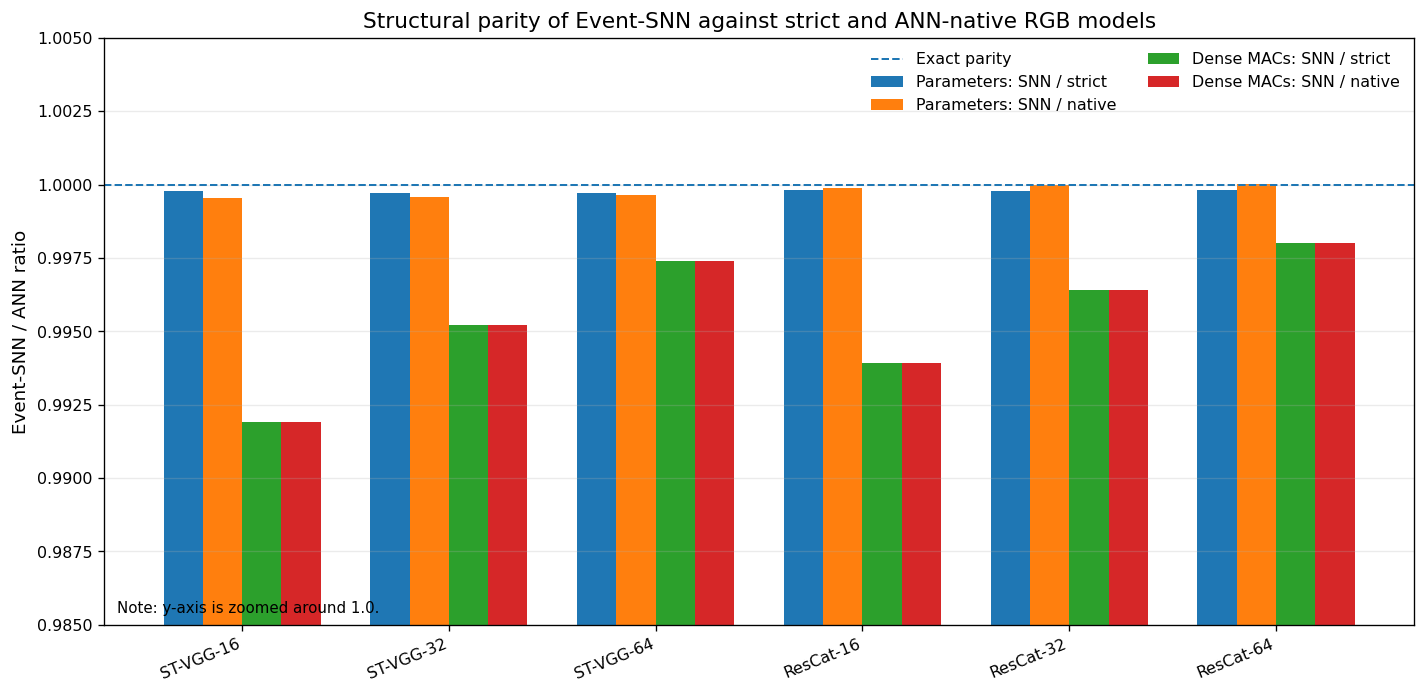

In [103]:
p=ordered_pairs(); x=np.arange(6); w=0.19
series=[
    ('params_A_over_B','Parameters: SNN / strict'),
    ('params_A_over_C','Parameters: SNN / native'),
    ('dense_macs_A_over_B','Dense MACs: SNN / strict'),
    ('dense_macs_A_over_C','Dense MACs: SNN / native'),
]
fig,ax=plt.subplots(figsize=(12.0,5.9))
for j,(col,label) in enumerate(series):
    vals=pd.to_numeric(p[col],errors='coerce').to_numpy(dtype=float)
    ax.bar(x+(j-1.5)*w,vals,width=w,label=label)
ax.axhline(1.0,linestyle='--',linewidth=1.2,label='Exact parity')
ax.set_xticks(x,[VARIANT_LABEL[v] for v in VARIANT_ORDER],rotation=22,ha='right')
ax.set_ylabel('Event-SNN / ANN ratio')
ax.set_ylim(0.985,1.005)
ax.set_title('Structural parity of Event-SNN against strict and ANN-native RGB models')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False,ncol=2)
ax.text(0.01,0.02,'Note: y-axis is zoomed around 1.0.',transform=ax.transAxes,fontsize=9)
fig.tight_layout(); save_fig(fig,'fig_01_structural_parity_scope_clean'); plt.show()
p[['variant']+[c for c,_ in series]].to_csv(FIG_DIR/'fig_01_structural_parity_scope_clean_source.csv',index=False)


### Figure 2 — Dense architecture cost and measured activity-dependent Event-SNN computation

The dense-equivalent bars describe architecture size; the effective Event-SNN bar uses measured spike activity. This is a computational comparison, not a hardware-energy comparison.


saved: /content/efod_results/thesis_figures/fig_02_computation_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_02_computation_scope_clean.pdf


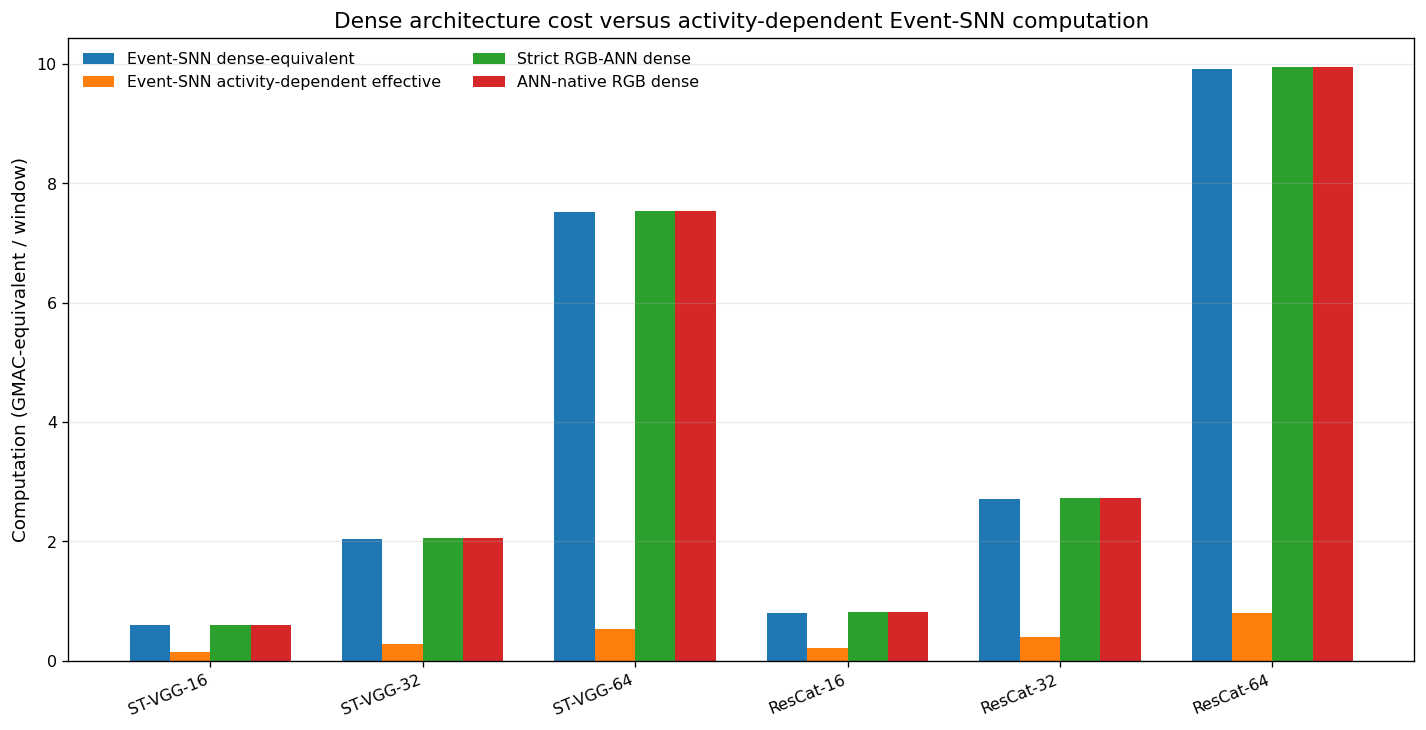

In [104]:
labels=[VARIANT_LABEL[v] for v in VARIANT_ORDER]; x=np.arange(6); w=0.19
snn_dense=ordered_pipeline('dense_gmacs','event_snn')
snn_eff=ordered_pipeline('effective_macs_ch6','event_snn')/1e9
strict_dense=ordered_pipeline('dense_gmacs','strict_ann')
native_dense=ordered_pipeline('dense_gmacs','native_ann')
vals=[snn_dense,snn_eff,strict_dense,native_dense]
names=['Event-SNN dense-equivalent','Event-SNN activity-dependent effective','Strict RGB-ANN dense','ANN-native RGB dense']
fig,ax=plt.subplots(figsize=(12.0,6.2))
for j,(y,name) in enumerate(zip(vals,names)):
    ax.bar(x+(j-1.5)*w,y,width=w,label=name)
ax.set_xticks(x,labels,rotation=22,ha='right')
ax.set_ylabel('Computation (GMAC-equivalent / window)')
ax.set_title('Dense architecture cost versus activity-dependent Event-SNN computation')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False,ncol=2)
fig.tight_layout(); save_fig(fig,'fig_02_computation_scope_clean'); plt.show()
pd.DataFrame({
    'variant':VARIANT_ORDER,
    'event_snn_dense_gmac':snn_dense,
    'event_snn_effective_gmac':snn_eff,
    'strict_ann_dense_gmac':strict_dense,
    'native_ann_dense_gmac':native_dense,
}).to_csv(FIG_DIR/'fig_02_computation_scope_clean_source.csv',index=False)


### Figure 3 — Layer-wise SNN spike-rate heatmap

Each column is the chronological PLIF-layer index within a model. This makes dead/near-dead layers visible instead of hiding them behind a single global firing-rate number. Because ST-VGG and ResCat do not have identical layer names, the heatmap compares **ordered PLIF positions**; the accompanying CSV preserves the original layer names.


saved: /content/efod_results/thesis_figures/fig_03_layerwise_spike_rate_heatmap.png
saved: /content/efod_results/thesis_figures/fig_03_layerwise_spike_rate_heatmap.pdf


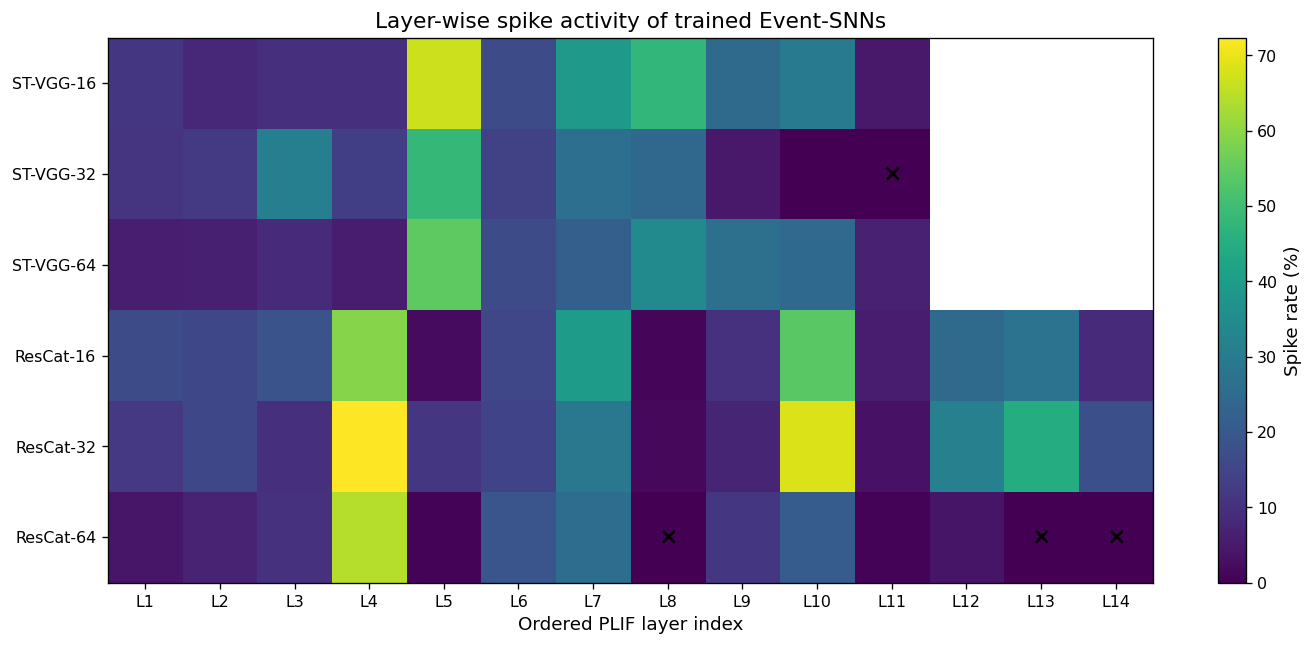

In [106]:
summary_dir = RESULTS_DIR / 'spike_activity_summary'
if not summary_dir.exists():
    raise FileNotFoundError(f'Missing {summary_dir}. Run the trained Event-SNN benchmark first.')

layer_rows = []
for variant in VARIANT_ORDER:
    f = summary_dir / f'{variant}_event_snn.csv'
    if not f.exists():
        raise FileNotFoundError(f'Missing per-layer activity summary: {f}')
    t = pd.read_csv(f)
    if 'rate_pct' in t.columns:
        rate_pct = pd.to_numeric(t['rate_pct'], errors='coerce')
    elif 'rate' in t.columns:
        rate_pct = 100.0 * pd.to_numeric(t['rate'], errors='coerce')
    else:
        raise KeyError(f'Expected rate_pct or rate in {f}; columns={list(t.columns)}')
    for j, (idx, row) in enumerate(t.iterrows(), start=1):
        layer_rows.append({
            'variant': variant,
            'model_label': VARIANT_LABEL[variant],
            'plif_index': j,
            'layer_name': row.get('name', f'PLIF {j}'),
            'rate_pct': float(rate_pct.loc[idx]) if pd.notna(rate_pct.loc[idx]) else np.nan,
            'dead': bool(row.get('dead', False)),
            'near_dead': bool(row.get('near_dead', False)),
            'saturated': bool(row.get('saturated', False)),
        })

layer_df = pd.DataFrame(layer_rows)
heat = layer_df.pivot(index='model_label', columns='plif_index', values='rate_pct')
heat = heat.reindex([VARIANT_LABEL[v] for v in VARIANT_ORDER])

fig, ax = plt.subplots(figsize=(12,5.5))
masked = np.ma.masked_invalid(heat.to_numpy(dtype=float))
im = ax.imshow(masked, aspect='auto', interpolation='nearest', vmin=0, vmax=max(70, np.nanmax(masked)))
cb = fig.colorbar(im, ax=ax)
cb.set_label('Spike rate (%)')
ax.set_yticks(np.arange(len(heat.index)), heat.index)
ax.set_xticks(np.arange(len(heat.columns)), [f'L{i}' for i in heat.columns])
ax.set_xlabel('Ordered PLIF layer index')
ax.set_title('Layer-wise spike activity of trained Event-SNNs')

# Mark dead/near-dead layer positions with an x for diagnostic visibility.
for _, r in layer_df.iterrows():
    if r['dead'] or r['near_dead']:
        yi = list(heat.index).index(r['model_label'])
        xi = list(heat.columns).index(r['plif_index'])
        ax.text(xi, yi, '×', ha='center', va='center', fontsize=14, fontweight='bold')

fig.tight_layout()
save_fig(fig, 'fig_03_layerwise_spike_rate_heatmap')
plt.show()
layer_df.to_csv(FIG_DIR/'fig_03_layerwise_spike_rate_source.csv', index=False)


### Figure 4 — Measured T4 full-detector energy ratios against both ANN baselines

This figure stays entirely inside one evidence group: all values are **full-detector NVIDIA T4/NVML measurements** obtained with the same protocol. Values below 1 favor the Event-SNN on the measured GPU.


saved: /content/efod_results/thesis_figures/fig_04_gpu_energy_ratios_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_04_gpu_energy_ratios_scope_clean.pdf


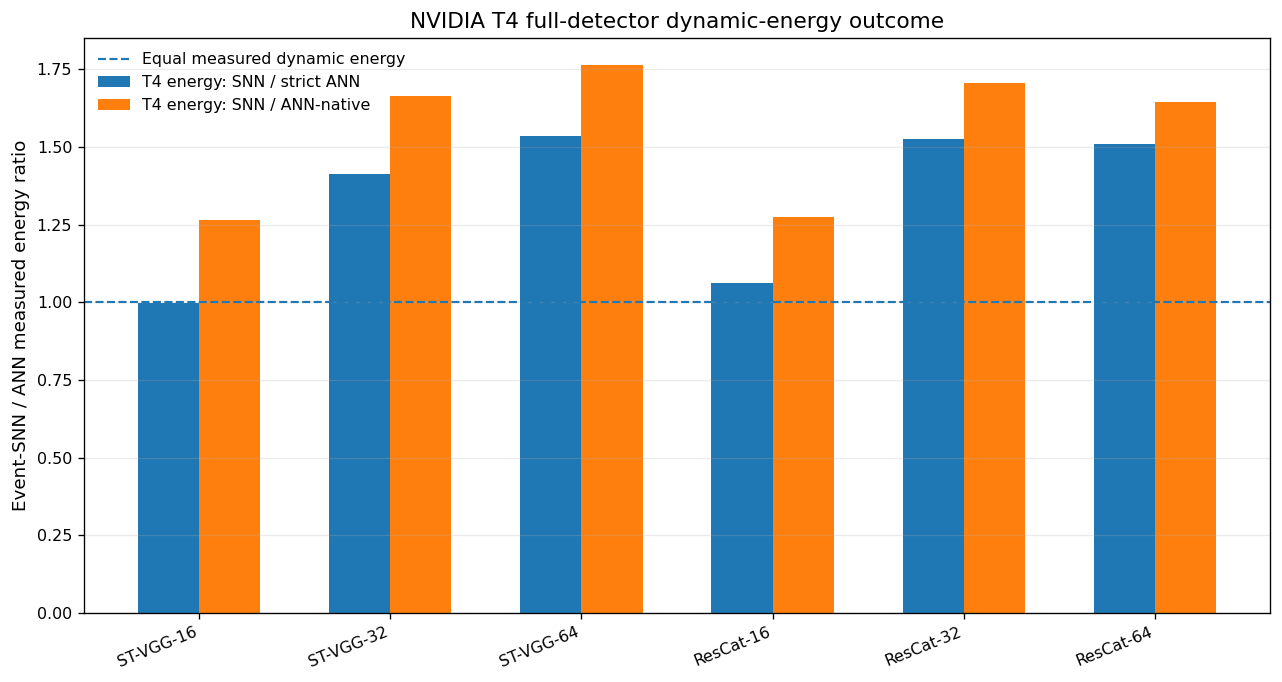

In [107]:
p=ordered_pairs(); x=np.arange(6); w=0.32
series=[
    ('gpu_dynamic_energy_A_over_B','T4 energy: SNN / strict ANN'),
    ('gpu_dynamic_energy_A_over_C','T4 energy: SNN / ANN-native'),
]
fig,ax=plt.subplots(figsize=(10.8,5.8))
for j,(col,label) in enumerate(series):
    vals=pd.to_numeric(p[col],errors='coerce').to_numpy(dtype=float)
    ax.bar(x+(j-0.5)*w,vals,width=w,label=label)
ax.axhline(1.0,linestyle='--',linewidth=1.3,label='Equal measured dynamic energy')
ax.set_xticks(x,[VARIANT_LABEL[v] for v in VARIANT_ORDER],rotation=22,ha='right')
ax.set_ylabel('Event-SNN / ANN measured energy ratio')
ax.set_title('NVIDIA T4 full-detector dynamic-energy outcome')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig,'fig_04_gpu_energy_ratios_scope_clean'); plt.show()
p[['variant']+[c for c,_ in series]].to_csv(FIG_DIR/'fig_04_gpu_energy_ratios_scope_clean_source.csv',index=False)


### Figure 5 — Measured T4 full-detector dynamic energy with 95% confidence intervals

All A/B/C bars use the same full-detector NVML measurement protocol. Error bars are the reported 95% confidence intervals.


saved: /content/efod_results/thesis_figures/fig_05_gpu_dynamic_energy_ci95_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_05_gpu_dynamic_energy_ci95_scope_clean.pdf


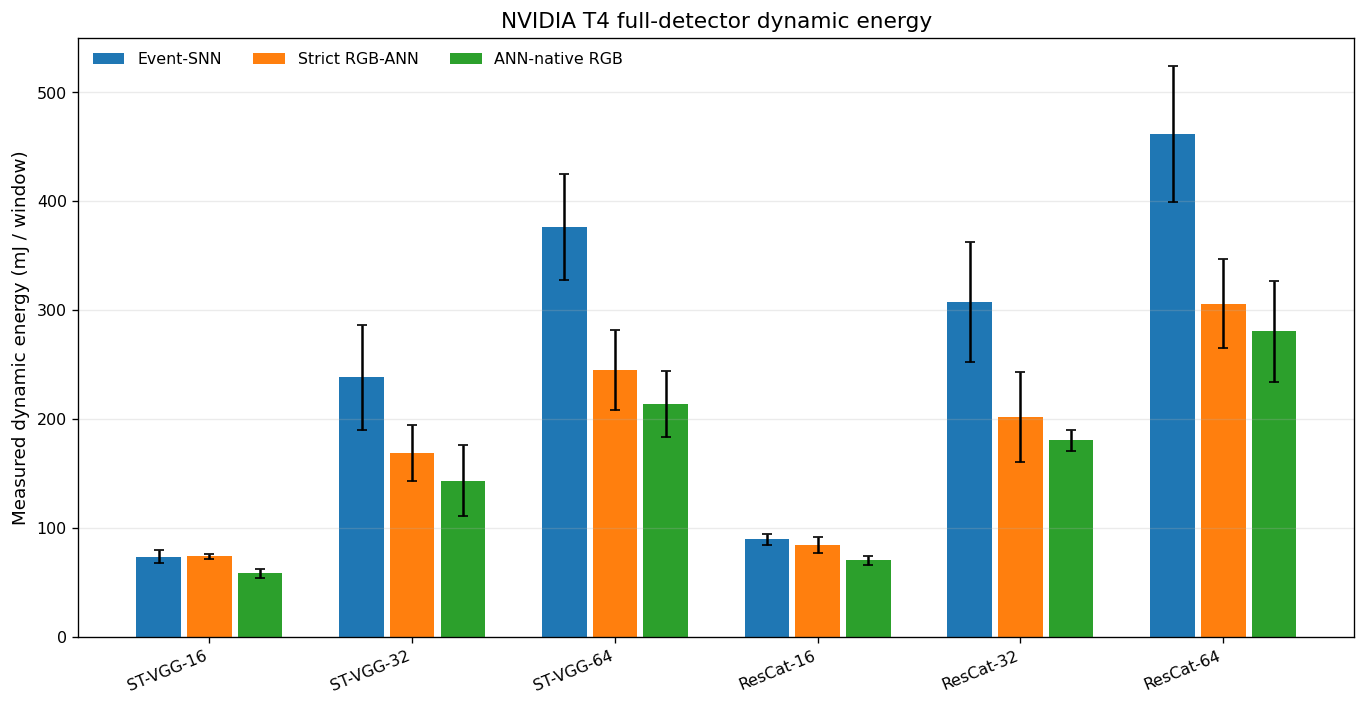

In [108]:
centers,offsets=grouped_positions(width=0.25)
labels=[VARIANT_LABEL[v] for v in VARIANT_ORDER]
fig,ax=plt.subplots(figsize=(11.5,6.0)); rows=[]
for j,pipeline in enumerate(PIPELINE_ORDER):
    y=ordered_pipeline('gpu_seq_energy_dynamic_mj',pipeline)
    low=ordered_pipeline('gpu_seq_energy_dynamic_ci95_low_mj',pipeline)
    high=ordered_pipeline('gpu_seq_energy_dynamic_ci95_high_mj',pipeline)
    yerr=np.vstack([np.maximum(0,y-low),np.maximum(0,high-y)])
    xpos=centers+offsets[j]
    ax.bar(xpos,y,width=0.22,label=PIPELINE_LABEL[pipeline],yerr=yerr,capsize=3,color=PIPELINE_COLOR[pipeline])
    for v,yy,ll,hh in zip(VARIANT_ORDER,y,low,high):
        rows.append({'variant':v,'pipeline':pipeline,'mean_mJ':yy,'ci95_low_mJ':ll,'ci95_high_mJ':hh})
ax.set_xticks(centers,labels,rotation=22,ha='right')
ax.set_ylabel('Measured dynamic energy (mJ / window)')
ax.set_title('NVIDIA T4 full-detector dynamic energy')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False,ncol=3)
fig.tight_layout(); save_fig(fig,'fig_05_gpu_dynamic_energy_ci95_scope_clean'); plt.show()
pd.DataFrame(rows).to_csv(FIG_DIR/'fig_05_gpu_dynamic_energy_ci95_scope_clean_source.csv',index=False)


### Figure 6 — Measured T4 full-detector streaming latency and the 50-ms input-window reference

All bars use the same measured full-detector GPU scope. The 50-ms line is an application-time reference, not a claim about neuromorphic hardware.


saved: /content/efod_results/thesis_figures/fig_06_gpu_stream_latency_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_06_gpu_stream_latency_scope_clean.pdf


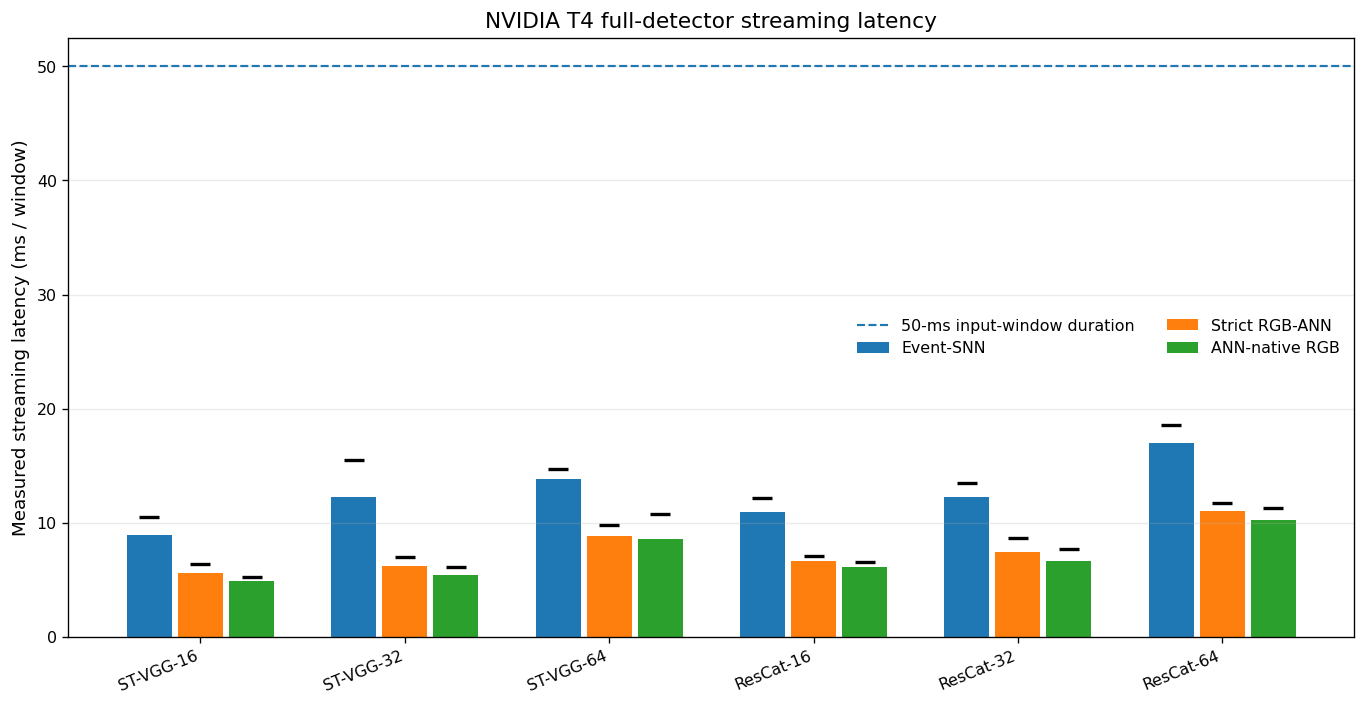

In [109]:
centers,offsets=grouped_positions(width=0.25)
labels=[VARIANT_LABEL[v] for v in VARIANT_ORDER]
fig,ax=plt.subplots(figsize=(11.5,6.0)); rows=[]
for j,pipeline in enumerate(PIPELINE_ORDER):
    mean=ordered_pipeline('seq_latency_stream_mean_ms',pipeline)
    p95=ordered_pipeline('seq_latency_stream_p95_ms',pipeline)
    xpos=centers+offsets[j]
    ax.bar(xpos,mean,width=0.22,label=PIPELINE_LABEL[pipeline],color=PIPELINE_COLOR[pipeline])
    ax.scatter(xpos,p95,marker='_',s=150,linewidths=2,color='black',zorder=4)
    for v,m,q in zip(VARIANT_ORDER,mean,p95): rows.append({'variant':v,'pipeline':pipeline,'mean_ms':m,'p95_ms':q})
ax.axhline(50.0,linewidth=1.3,linestyle='--',label='50-ms input-window duration')
ax.set_xticks(centers,labels,rotation=22,ha='right')
ax.set_ylabel('Measured streaming latency (ms / window)')
ax.set_title('NVIDIA T4 full-detector streaming latency')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False,ncol=2)
fig.tight_layout(); save_fig(fig,'fig_06_gpu_stream_latency_scope_clean'); plt.show()
pd.DataFrame(rows).to_csv(FIG_DIR/'fig_06_gpu_stream_latency_scope_clean_source.csv',index=False)


### Figure 7 — Memory footprint: parameters plus SNN membrane state

Parameter memory is shown for all pipelines. The hatched upper section is the additional membrane-state storage required by the stateful Event-SNN.


saved: /content/efod_results/thesis_figures/fig_07_memory_parameters_plus_snn_state.png
saved: /content/efod_results/thesis_figures/fig_07_memory_parameters_plus_snn_state.pdf


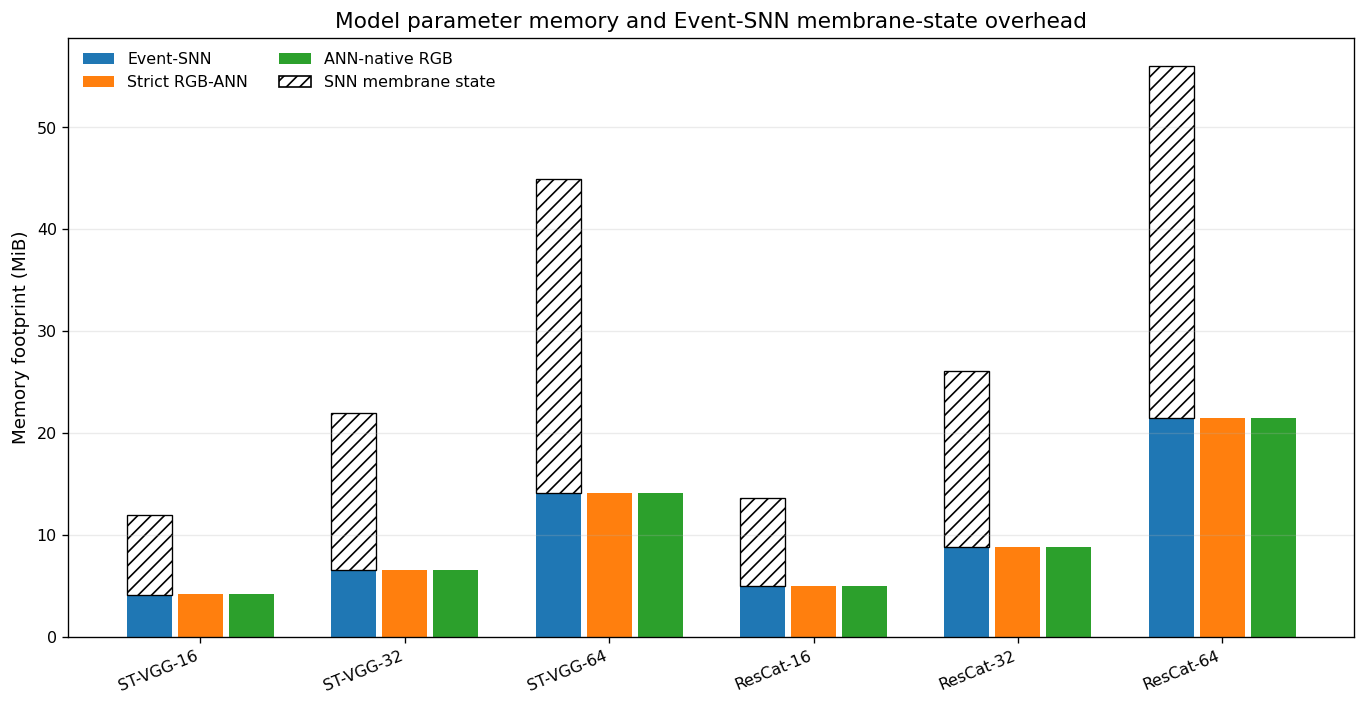

In [111]:
centers, offsets = grouped_positions(width=0.25)
labels = [VARIANT_LABEL[v] for v in VARIANT_ORDER]
fig, ax = plt.subplots(figsize=(11.5,6.0))
source_rows=[]

for j, pipeline in enumerate(PIPELINE_ORDER):
    param = ordered_pipeline('fp32_param_mib', pipeline)
    state = ordered_pipeline('snn_state_mib', pipeline) if 'snn_state_mib' in df.columns else np.zeros_like(param)
    xpos = centers + offsets[j]
    ax.bar(xpos, param, width=0.22, color=PIPELINE_COLOR[pipeline], label=PIPELINE_LABEL[pipeline])
    if np.nanmax(state) > 0:
        ax.bar(xpos, state, width=0.22, bottom=param, facecolor='none', edgecolor='black', hatch='///', linewidth=0.8)
    for v, pp, ss in zip(VARIANT_ORDER, param, state):
        source_rows.append({'variant':v,'pipeline':pipeline,'fp32_parameter_MiB':pp,'membrane_state_MiB':ss,'total_MiB':pp+ss})

ax.set_xticks(centers, labels, rotation=22, ha='right')
ax.set_ylabel('Memory footprint (MiB)')
ax.set_title('Model parameter memory and Event-SNN membrane-state overhead')
ax.grid(axis='y', alpha=0.25)
legend_handles = [Patch(facecolor=PIPELINE_COLOR[p], label=PIPELINE_LABEL[p]) for p in PIPELINE_ORDER]
legend_handles.append(Patch(facecolor='none', edgecolor='black', hatch='///', label='SNN membrane state'))
ax.legend(handles=legend_handles, frameon=False, ncol=2)
fig.tight_layout()
save_fig(fig, 'fig_07_memory_parameters_plus_snn_state')
plt.show()
pd.DataFrame(source_rows).to_csv(FIG_DIR/'fig_07_memory_source.csv', index=False)


### Figure 8 — Measured T4 full-detector latency–energy operating points

Both axes come from the same conventional-GPU evidence group. Lower-left is preferable on the measured NVIDIA T4.


saved: /content/efod_results/thesis_figures/fig_08_gpu_latency_energy_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_08_gpu_latency_energy_scope_clean.pdf


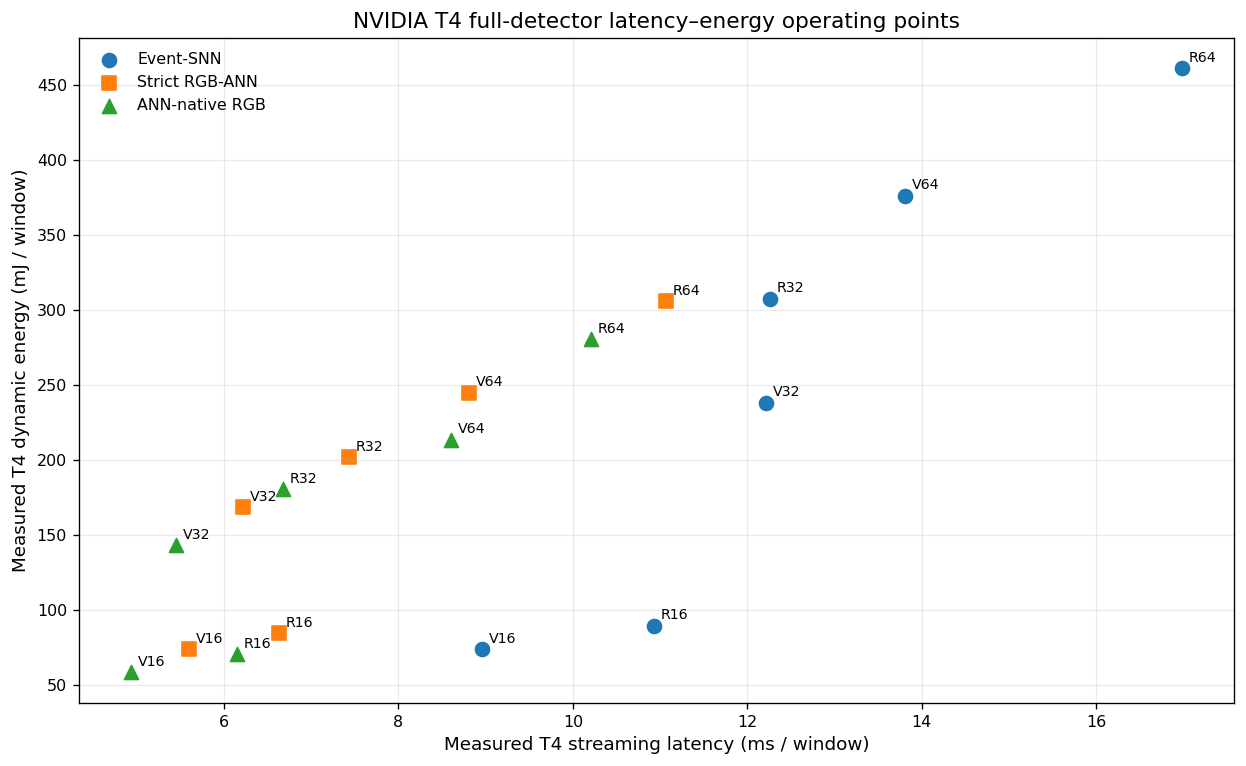

In [112]:
fig,ax=plt.subplots(figsize=(10.5,6.5)); rows=[]
for pipeline in PIPELINE_ORDER:
    sub=df[df['pipeline']==pipeline].copy(); sub['variant']=sub['variant'].astype(str).str.lower()
    sub=sub.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    x=pd.to_numeric(sub['seq_latency_stream_mean_ms'],errors='coerce').to_numpy(dtype=float)
    y=pd.to_numeric(sub['gpu_seq_energy_dynamic_mj'],errors='coerce').to_numpy(dtype=float)
    ax.scatter(x,y,s=70,marker=PIPELINE_MARKER[pipeline],color=PIPELINE_COLOR[pipeline],label=PIPELINE_LABEL[pipeline])
    for v,xx,yy in zip(VARIANT_ORDER,x,y):
        short={'vgg16':'V16','vgg32':'V32','vgg64':'V64','rescat16':'R16','rescat32':'R32','rescat64':'R64'}[v]
        ax.annotate(short,(xx,yy),xytext=(4,4),textcoords='offset points',fontsize=8.5)
        rows.append({'variant':v,'pipeline':pipeline,'latency_ms':xx,'dynamic_energy_mJ':yy})
ax.set_xlabel('Measured T4 streaming latency (ms / window)')
ax.set_ylabel('Measured T4 dynamic energy (mJ / window)')
ax.set_title('NVIDIA T4 full-detector latency–energy operating points')
ax.grid(alpha=0.25); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig,'fig_08_gpu_latency_energy_scope_clean'); plt.show()
pd.DataFrame(rows).to_csv(FIG_DIR/'fig_08_gpu_latency_energy_scope_clean_source.csv',index=False)


### Figure 9 — Lemaire-style analytical full-detector energy breakdown

The same analytical model decomposes each A/B/C full detector into memory, synaptic-operation, and sparse-addressing terms. This explains the analytical estimate internally; it is not a comparison to SANA-FE.


saved: /content/efod_results/thesis_figures/fig_09_analytical_energy_breakdown.png
saved: /content/efod_results/thesis_figures/fig_09_analytical_energy_breakdown.pdf


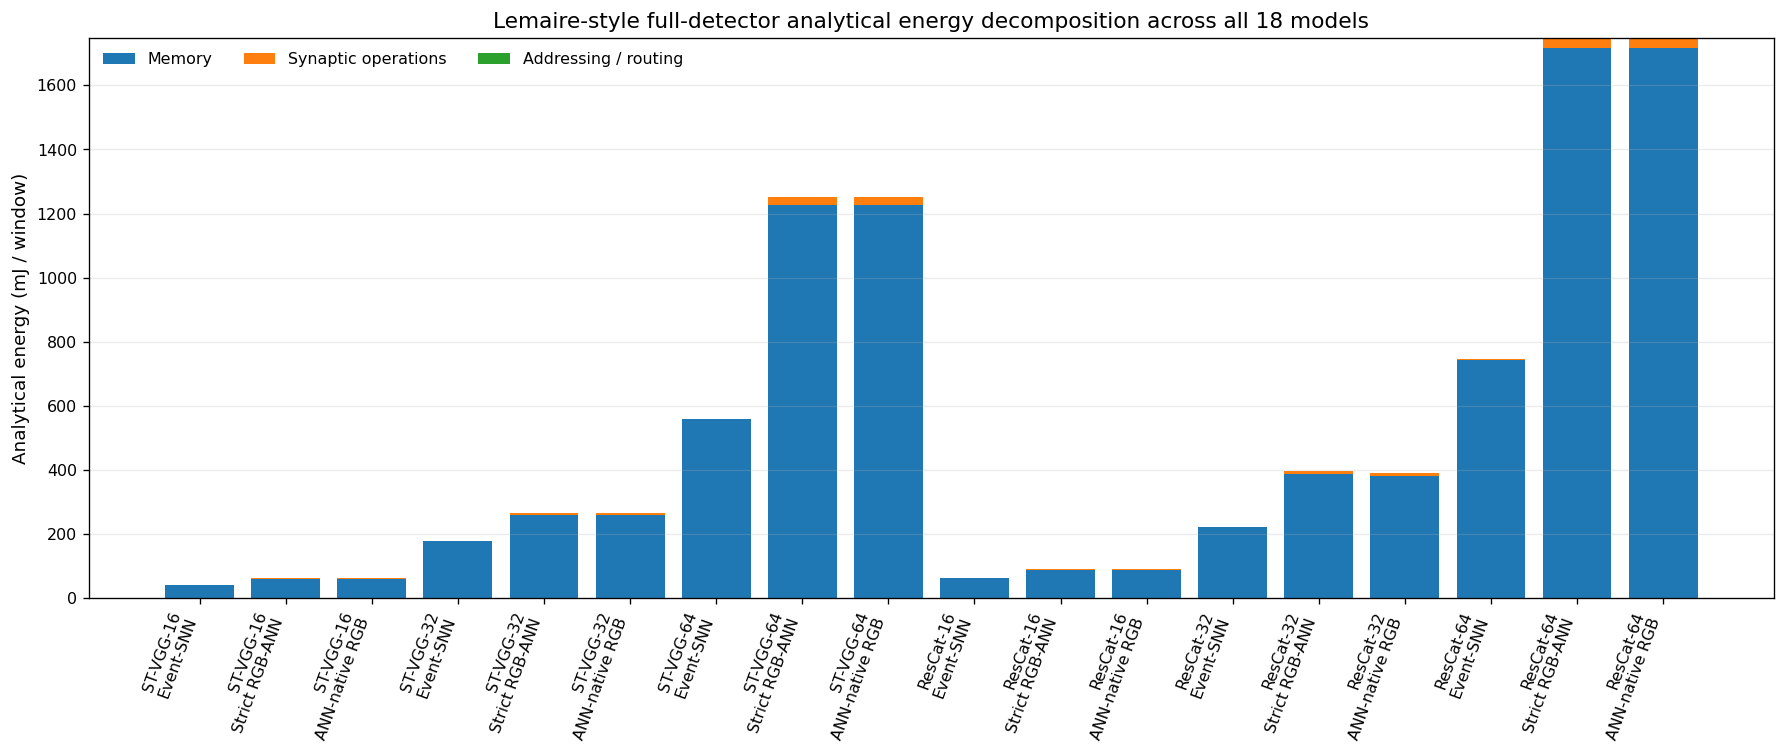

In [113]:
# 18 compact bars ordered by architecture and pipeline.
rows=[]
for v in VARIANT_ORDER:
    for p_name in PIPELINE_ORDER:
        r = df[(df['variant'].astype(str).str.lower()==v) & (df['pipeline']==p_name)]
        if len(r)!=1:
            raise ValueError(f'Expected one row for {v}/{p_name}, found {len(r)}')
        r=r.iloc[0]
        rows.append({
            'label': f"{VARIANT_LABEL[v]}\n{PIPELINE_LABEL[p_name]}",
            'variant':v, 'pipeline':p_name,
            'memory_mJ': float(r['thesis_memory_uJ'])/1000.0,
            'synaptic_mJ': float(r['thesis_synaptic_uJ'])/1000.0,
            'address_mJ': float(r['thesis_address_uJ'])/1000.0,
        })
e = pd.DataFrame(rows)
x=np.arange(len(e))

fig, ax = plt.subplots(figsize=(15,6.4))
bottom=np.zeros(len(e))
for col,label in [('memory_mJ','Memory'),('synaptic_mJ','Synaptic operations'),('address_mJ','Addressing / routing')]:
    vals=e[col].to_numpy(dtype=float)
    ax.bar(x, vals, bottom=bottom, label=label)
    bottom += vals
ax.set_xticks(x, e['label'], rotation=70, ha='right')
ax.set_ylabel('Analytical energy (mJ / window)')
ax.set_title('Lemaire-style full-detector analytical energy decomposition across all 18 models')
ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
save_fig(fig, 'fig_09_analytical_energy_breakdown')
plt.show()
e.to_csv(FIG_DIR/'fig_09_analytical_energy_breakdown_source.csv', index=False)


### Figure 10 — Lemaire-style analytical full-detector energy ratios against both ANN baselines

All bars are generated by the **same analytical model** and cover the **same full-detector scope**. They should be interpreted only inside that analytical model, not as measured hardware energy.


saved: /content/efod_results/thesis_figures/fig_10_analytical_energy_ratios_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_10_analytical_energy_ratios_scope_clean.pdf


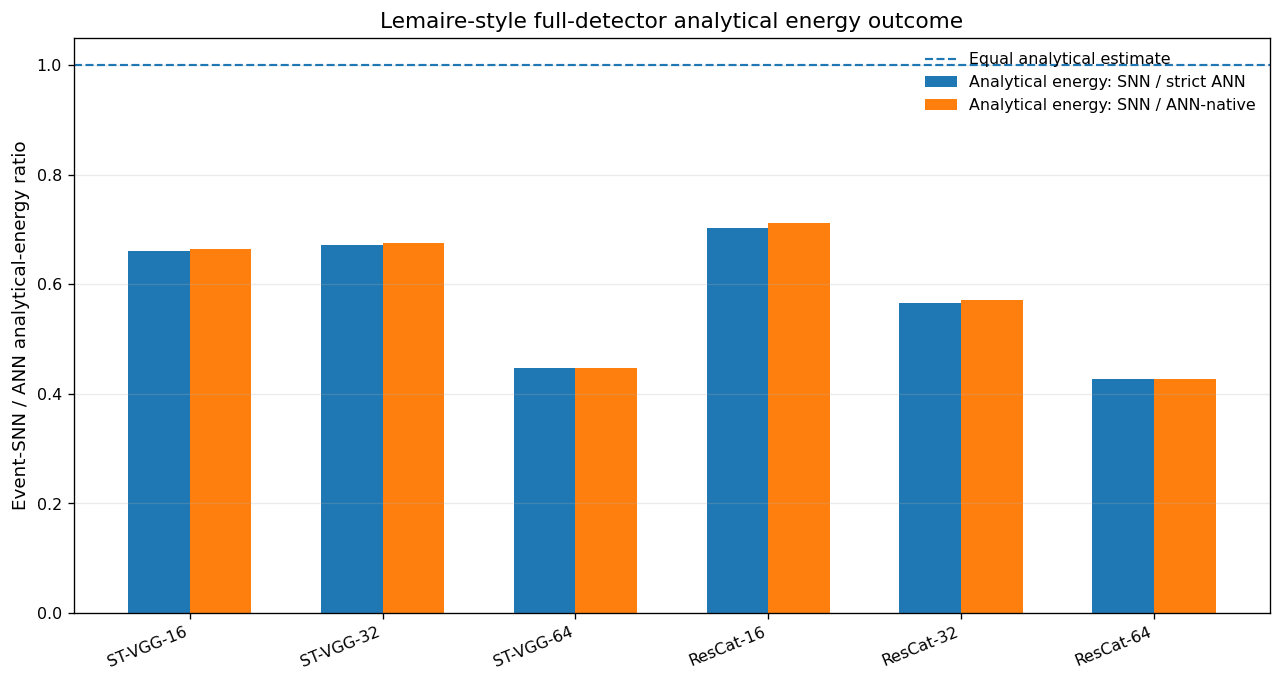

In [114]:
p=ordered_pairs(); x=np.arange(6); w=0.32
series=[
    ('thesis_energy_A_over_B','Analytical energy: SNN / strict ANN'),
    ('thesis_energy_A_over_C','Analytical energy: SNN / ANN-native'),
]
fig,ax=plt.subplots(figsize=(10.8,5.8))
for j,(col,label) in enumerate(series):
    vals=pd.to_numeric(p[col],errors='coerce').to_numpy(dtype=float)
    ax.bar(x+(j-0.5)*w,vals,width=w,label=label)
ax.axhline(1.0,linestyle='--',linewidth=1.3,label='Equal analytical estimate')
ax.set_xticks(x,[VARIANT_LABEL[v] for v in VARIANT_ORDER],rotation=22,ha='right')
ax.set_ylabel('Event-SNN / ANN analytical-energy ratio')
ax.set_title('Lemaire-style full-detector analytical energy outcome')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig,'fig_10_analytical_energy_ratios_scope_clean'); plt.show()
p[['variant']+[c for c,_ in series]].to_csv(FIG_DIR/'fig_10_analytical_energy_ratios_scope_clean_source.csv',index=False)


### Figure 11 — Absolute Lemaire-style analytical energy for all A/B/C full detectors

This figure remains entirely within the analytical evidence group and uses the same energy model for all 18 models.


saved: /content/efod_results/thesis_figures/fig_11_analytical_energy_absolute_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_11_analytical_energy_absolute_scope_clean.pdf


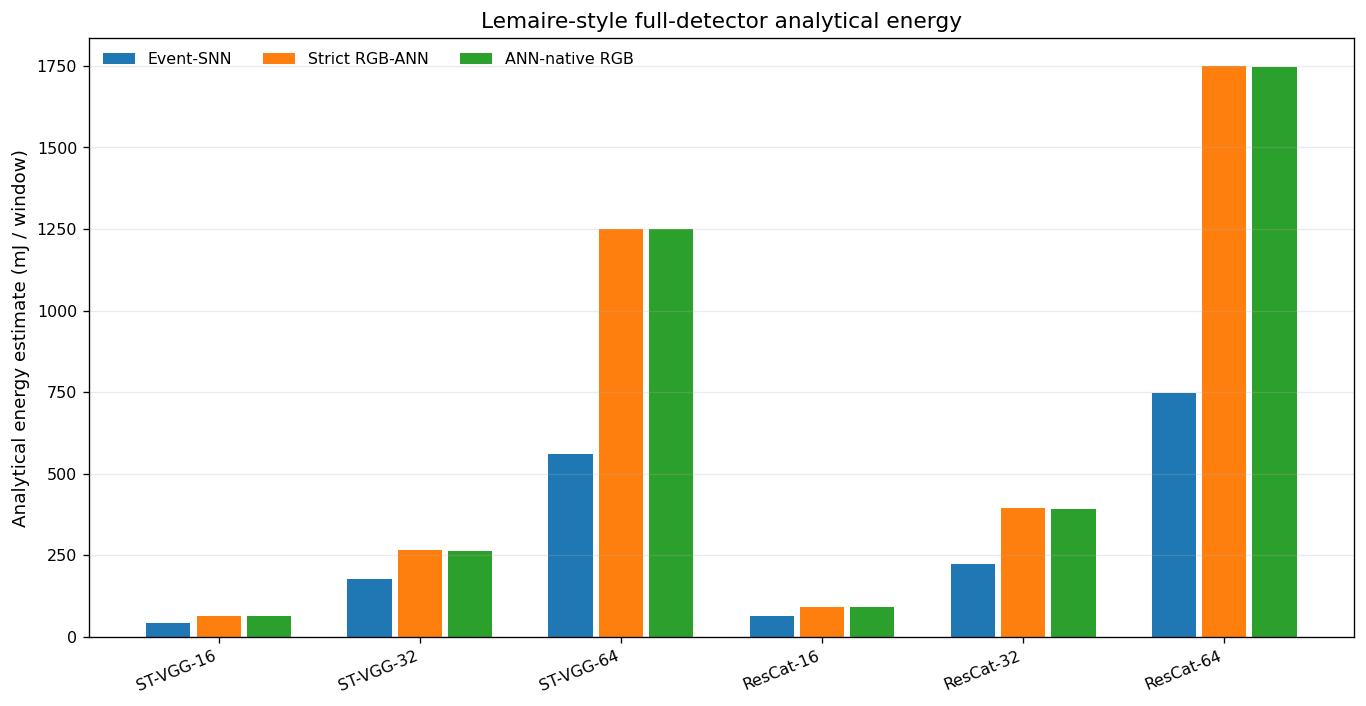

In [115]:
centers,offsets=grouped_positions(width=0.25)
fig,ax=plt.subplots(figsize=(11.5,6.0)); rows=[]
for j,pipeline in enumerate(PIPELINE_ORDER):
    y=ordered_pipeline('thesis_total_uJ',pipeline)/1000.0
    ax.bar(centers+offsets[j],y,width=0.22,label=PIPELINE_LABEL[pipeline],color=PIPELINE_COLOR[pipeline])
    for v,val in zip(VARIANT_ORDER,y): rows.append({'variant':v,'pipeline':pipeline,'analytical_total_mJ':val})
ax.set_xticks(centers,[VARIANT_LABEL[v] for v in VARIANT_ORDER],rotation=22,ha='right')
ax.set_ylabel('Analytical energy estimate (mJ / window)')
ax.set_title('Lemaire-style full-detector analytical energy')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False,ncol=3)
fig.tight_layout(); save_fig(fig,'fig_11_analytical_energy_absolute_scope_clean'); plt.show()
pd.DataFrame(rows).to_csv(FIG_DIR/'fig_11_analytical_energy_absolute_scope_clean_source.csv',index=False)


### Figure 12 — SANA-FE projected spiking-subgraph energy

This is **not** a full detector energy measurement. It is the notebook's layer-aggregated Loihi-1-like SANA-FE projection for the **spiking backbone + spiking SSD extra feature layers**, excluding the dense SSD prediction heads.


saved: /content/efod_results/thesis_figures/fig_12_sanafe_projected_spiking_subgraph_energy.png
saved: /content/efod_results/thesis_figures/fig_12_sanafe_projected_spiking_subgraph_energy.pdf


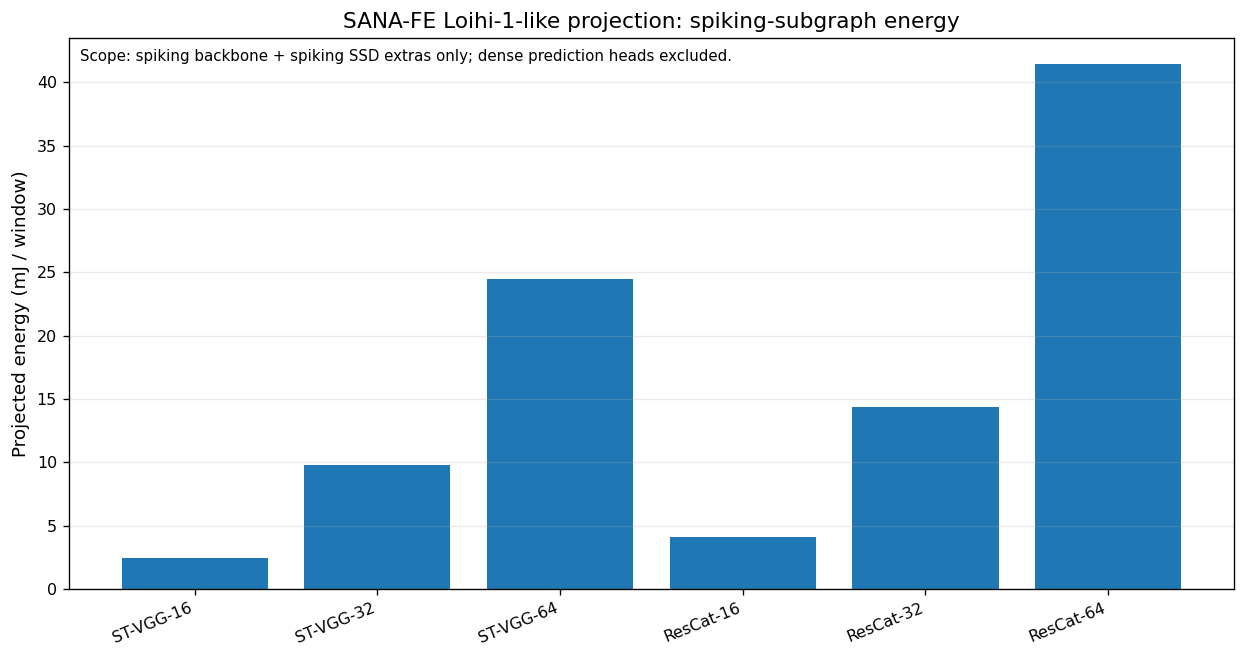

In [116]:
if sana is None:
    print('SANA-FE projection CSV is not available; run the SANA-FE section before this figure.')
else:
    s=sana.copy()
    s['variant']=s['variant'].astype(str).str.lower()
    s=s.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    metric='sanafe_projected_spiking_subgraph_energy_mJ_per_window'
    y=pd.to_numeric(s[metric],errors='coerce').to_numpy(dtype=float)
    labels=[VARIANT_LABEL[v] for v in VARIANT_ORDER]
    fig,ax=plt.subplots(figsize=(10.5,5.6))
    ax.bar(np.arange(6),y)
    ax.set_xticks(np.arange(6),labels,rotation=22,ha='right')
    ax.set_ylabel('Projected energy (mJ / window)')
    ax.set_title('SANA-FE Loihi-1-like projection: spiking-subgraph energy')
    ax.grid(axis='y',alpha=0.25)
    ax.text(0.01,0.98,'Scope: spiking backbone + spiking SSD extras only; dense prediction heads excluded.',
            transform=ax.transAxes,va='top',fontsize=9)
    fig.tight_layout()
    save_fig(fig,'fig_12_sanafe_projected_spiking_subgraph_energy')
    plt.show()
    s[['variant',metric]].to_csv(FIG_DIR/'fig_12_sanafe_energy_source.csv',index=False)


### Figure 13 — SANA-FE projected spiking-subgraph latency versus the 50-ms stream window

This is the SANA-FE compact proxy latency for the spiking subgraph. It is shown against the 50-ms event-window duration as a real-time reference, but it is **not measured Loihi latency** and has no directly simulated ANN counterpart in this notebook.


saved: /content/efod_results/thesis_figures/fig_13_sanafe_projected_spiking_subgraph_latency.png
saved: /content/efod_results/thesis_figures/fig_13_sanafe_projected_spiking_subgraph_latency.pdf


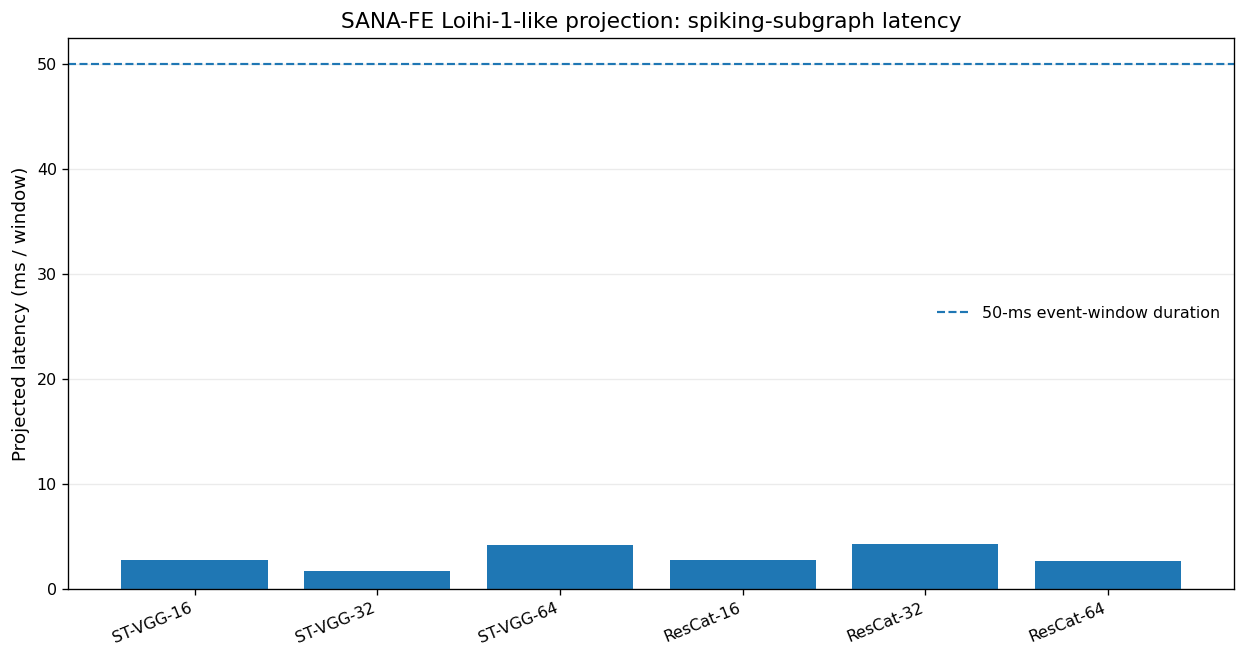

In [117]:
if sana is None:
    print('SANA-FE projection CSV is not available; run the SANA-FE section before this figure.')
else:
    s=sana.copy()
    s['variant']=s['variant'].astype(str).str.lower()
    s=s.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    metric='sanafe_projected_spiking_subgraph_latency_ms_per_window'
    y=pd.to_numeric(s[metric],errors='coerce').to_numpy(dtype=float)
    labels=[VARIANT_LABEL[v] for v in VARIANT_ORDER]
    fig,ax=plt.subplots(figsize=(10.5,5.6))
    ax.bar(np.arange(6),y)
    ax.axhline(50.0,linewidth=1.3,linestyle='--',label='50-ms event-window duration')
    ax.set_xticks(np.arange(6),labels,rotation=22,ha='right')
    ax.set_ylabel('Projected latency (ms / window)')
    ax.set_title('SANA-FE Loihi-1-like projection: spiking-subgraph latency')
    ax.grid(axis='y',alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    save_fig(fig,'fig_13_sanafe_projected_spiking_subgraph_latency')
    plt.show()
    s[['variant',metric]].to_csv(FIG_DIR/'fig_13_sanafe_latency_source.csv',index=False)


### Figure 14 — SANA-FE projected Event-SNN subgraph energy–latency operating points

Both axes come from the **same SANA-FE projection and the same spiking-subgraph scope**, so this is the appropriate SANA-FE trade-off view.


saved: /content/efod_results/thesis_figures/fig_14_sanafe_energy_latency_scope_clean.png
saved: /content/efod_results/thesis_figures/fig_14_sanafe_energy_latency_scope_clean.pdf


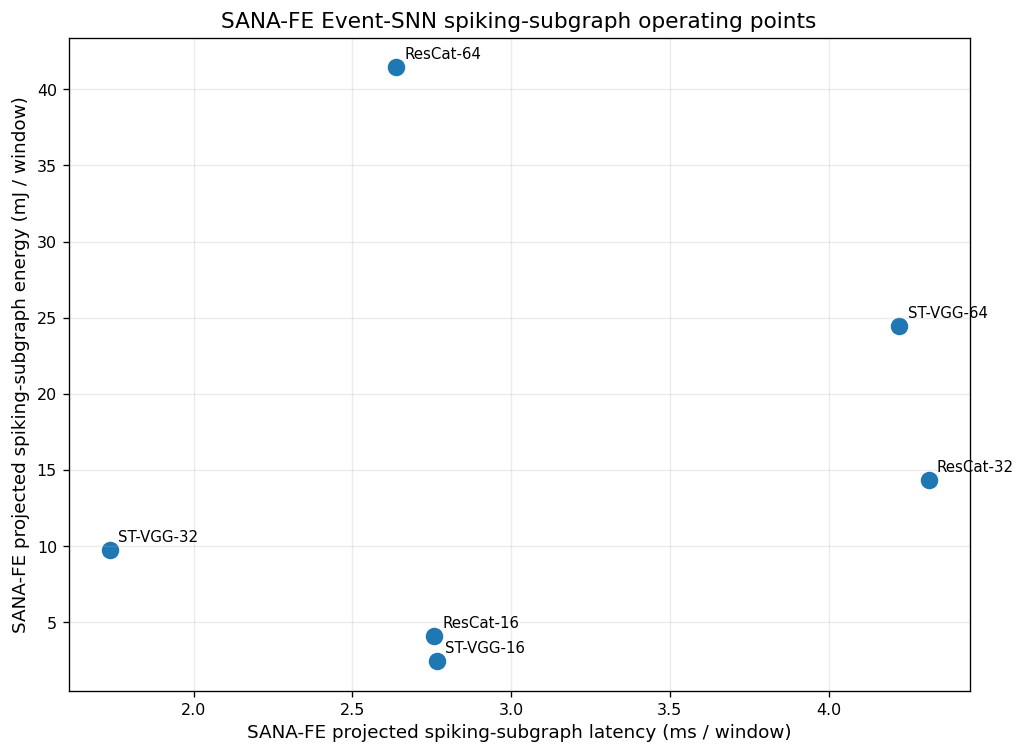

In [118]:
if sana is None:
    print('SANA-FE projection CSV is not available; run the SANA-FE section first.')
else:
    s=sana.copy(); s['variant']=s['variant'].astype(str).str.lower(); s=s.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    x=pd.to_numeric(s['sanafe_projected_spiking_subgraph_latency_ms_per_window'],errors='coerce').to_numpy(dtype=float)
    y=pd.to_numeric(s['sanafe_projected_spiking_subgraph_energy_mJ_per_window'],errors='coerce').to_numpy(dtype=float)
    fig,ax=plt.subplots(figsize=(8.7,6.4))
    ax.scatter(x,y,s=90)
    for v,xx,yy in zip(VARIANT_ORDER,x,y):
        ax.annotate(VARIANT_LABEL[v],(xx,yy),xytext=(5,5),textcoords='offset points',fontsize=9)
    ax.set_xlabel('SANA-FE projected spiking-subgraph latency (ms / window)')
    ax.set_ylabel('SANA-FE projected spiking-subgraph energy (mJ / window)')
    ax.set_title('SANA-FE Event-SNN spiking-subgraph operating points')
    ax.grid(alpha=0.25)
    fig.tight_layout(); save_fig(fig,'fig_14_sanafe_energy_latency_scope_clean'); plt.show()
    pd.DataFrame({'variant':VARIANT_ORDER,'projected_latency_ms':x,'projected_energy_mJ':y}).to_csv(
        FIG_DIR/'fig_14_sanafe_energy_latency_scope_clean_source.csv',index=False)


### Figure 15 — Event-SNN energy across three hardware/evidence viewpoints

This overview places the three energy viewpoints side-by-side for each SNN:

- measured T4 **full-detector** dynamic energy;
- Lemaire-style analytical analytical **full-detector** energy;
- SANA-FE projected **spiking-subgraph** energy.

Because SANA-FE excludes the dense prediction heads, this figure is intentionally a *hardware/evidence overview*, not an equal-scope energy benchmark. Figure 15 is the preferred same-scope analytical-versus-SANA-FE comparison.


saved: /content/efod_results/thesis_figures/fig_15_snn_energy_three_hardware_views.png
saved: /content/efod_results/thesis_figures/fig_15_snn_energy_three_hardware_views.pdf


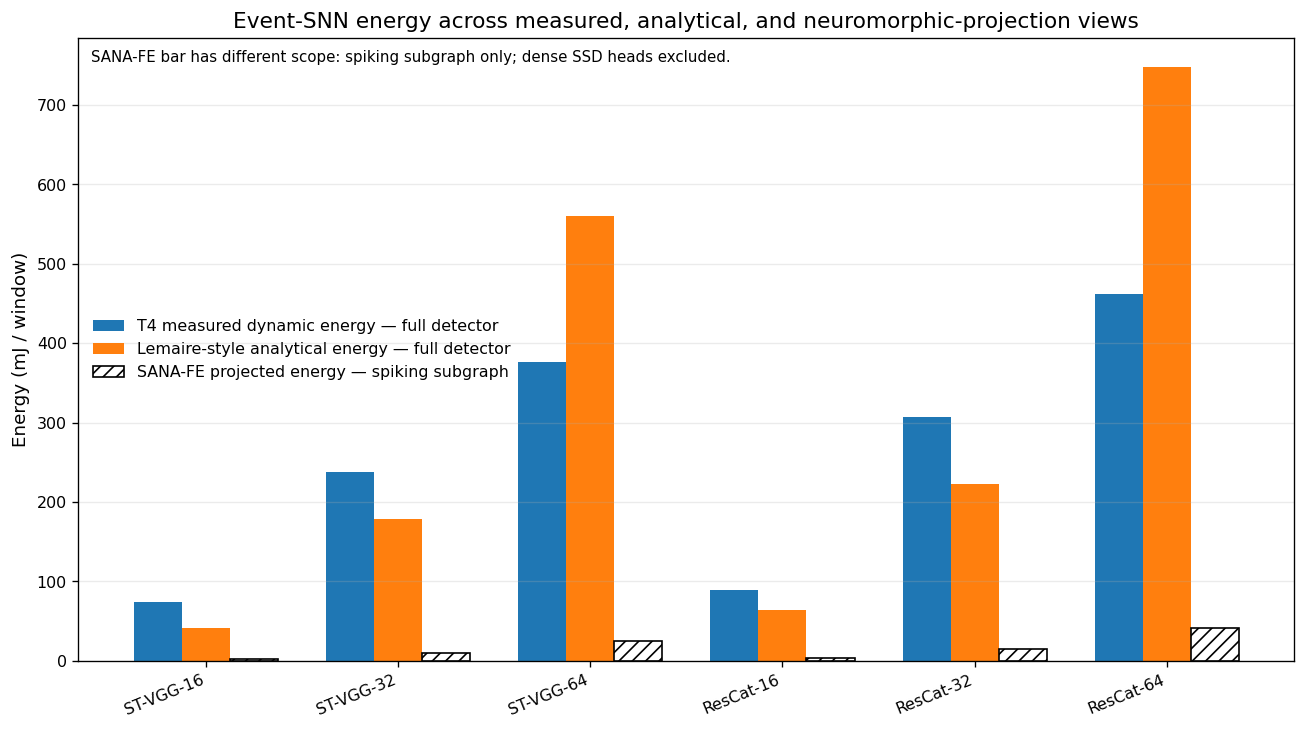

In [119]:
if sana is None:
    print('SANA-FE projection CSV is not available; run the SANA-FE section before this figure.')
else:
    s=sana.copy(); s['variant']=s['variant'].astype(str).str.lower(); s=s.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    gpu=ordered_pipeline('gpu_seq_energy_dynamic_mj','event_snn')
    analytical=ordered_pipeline('thesis_total_uJ','event_snn')/1000.0
    sf=pd.to_numeric(s['sanafe_projected_spiking_subgraph_energy_mJ_per_window'],errors='coerce').to_numpy(dtype=float)
    x=np.arange(6); w=0.25
    fig,ax=plt.subplots(figsize=(11.0,6.2))
    ax.bar(x-w,gpu,width=w,label='T4 measured dynamic energy — full detector')
    ax.bar(x,analytical,width=w,label='Lemaire-style analytical energy — full detector')
    ax.bar(x+w,sf,width=w,label='SANA-FE projected energy — spiking subgraph',hatch='///',facecolor='none',edgecolor='black')
    ax.set_xticks(x,[VARIANT_LABEL[v] for v in VARIANT_ORDER],rotation=22,ha='right')
    ax.set_ylabel('Energy (mJ / window)')
    ax.set_title('Event-SNN energy across measured, analytical, and neuromorphic-projection views')
    ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False)
    ax.text(0.01,0.98,'SANA-FE bar has different scope: spiking subgraph only; dense SSD heads excluded.',transform=ax.transAxes,va='top',fontsize=9)
    fig.tight_layout(); save_fig(fig,'fig_15_snn_energy_three_hardware_views'); plt.show()
    pd.DataFrame({'variant':VARIANT_ORDER,'gpu_full_detector_dynamic_mJ':gpu,'chapter6_full_detector_mJ':analytical,'sanafe_spiking_subgraph_mJ':sf}).to_csv(FIG_DIR/'fig_15_snn_energy_three_hardware_views_source.csv',index=False)


### Figure 16 — Energy outcome against **both** ANN baselines

The earlier hero figure used the strict ANN twin as the primary baseline. This expanded version includes the ANN-native RGB model as well. A ratio below 1 favors the Event-SNN; a ratio above 1 favors the corresponding ANN baseline.


saved: /content/efod_results/thesis_figures/fig_16_energy_ratios_strict_and_native_ann.png
saved: /content/efod_results/thesis_figures/fig_16_energy_ratios_strict_and_native_ann.pdf


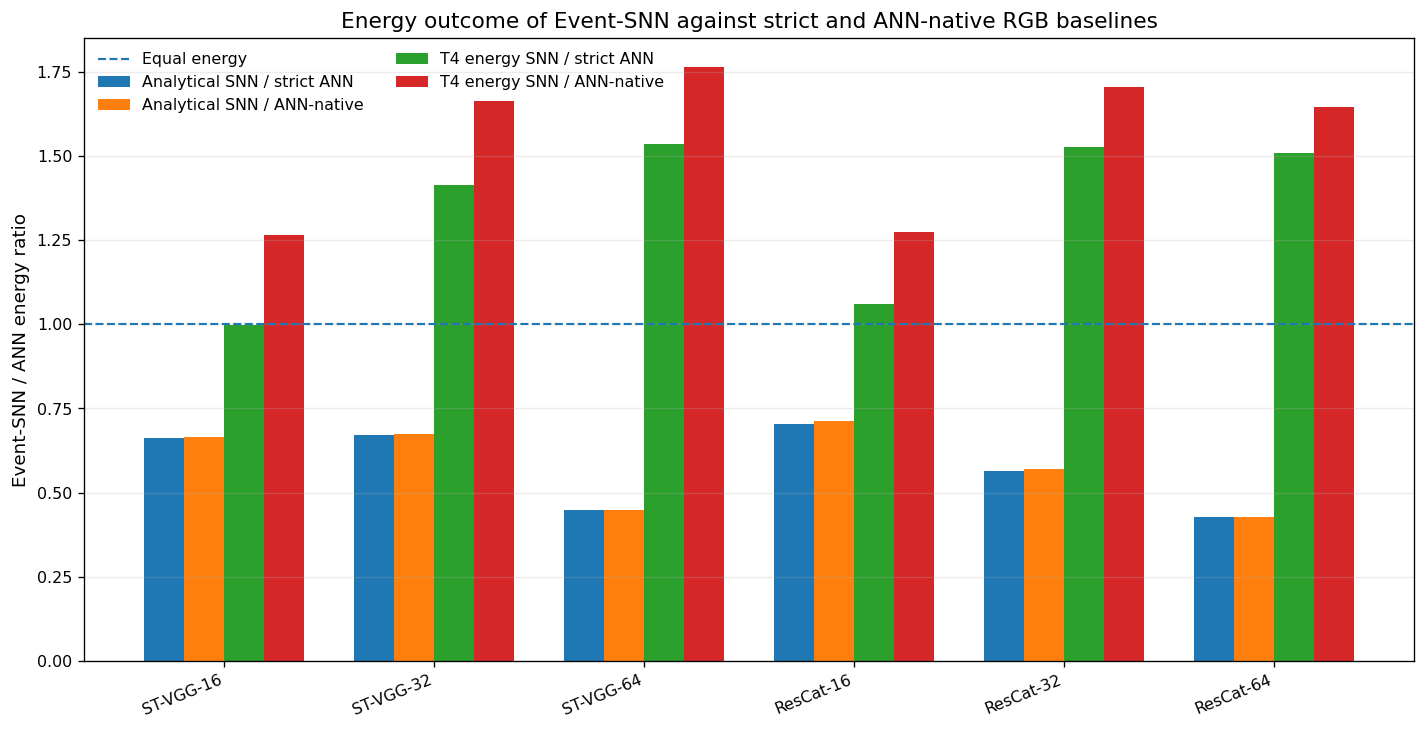

In [120]:
p=ordered_pairs(); x=np.arange(6); w=0.19
series=[
    ('thesis_energy_A_over_B','Analytical SNN / strict ANN'),
    ('thesis_energy_A_over_C','Analytical SNN / ANN-native'),
    ('gpu_dynamic_energy_A_over_B','T4 energy SNN / strict ANN'),
    ('gpu_dynamic_energy_A_over_C','T4 energy SNN / ANN-native'),
]
fig,ax=plt.subplots(figsize=(12.0,6.2))
for j,(col,label) in enumerate(series):
    vals=pd.to_numeric(p[col],errors='coerce').to_numpy(dtype=float)
    xpos=x+(j-1.5)*w
    ax.bar(xpos,vals,width=w,label=label)
ax.axhline(1.0,linestyle='--',linewidth=1.3,label='Equal energy')
ax.set_xticks(x,[VARIANT_LABEL[v] for v in VARIANT_ORDER],rotation=22,ha='right')
ax.set_ylabel('Event-SNN / ANN energy ratio')
ax.set_title('Energy outcome of Event-SNN against strict and ANN-native RGB baselines')
ax.grid(axis='y',alpha=0.25); ax.legend(frameon=False,ncol=2)
fig.tight_layout(); save_fig(fig,'fig_16_energy_ratios_strict_and_native_ann'); plt.show()
p[['variant']+[c for c,_ in series]].to_csv(FIG_DIR/'fig_16_energy_ratios_strict_and_native_source.csv',index=False)


### Figure 17 — Expanded cross-hardware ratio matrix: strict ANN **and** ANN-native baselines

Each pair of columns answers the same question against a different ANN baseline. Values below 1 favor the Event-SNN; values above 1 favor the ANN. This is the most compact summary of the full A/B/C experiment across computation, analytical energy, measured GPU latency, and measured GPU energy.


saved: /content/efod_results/thesis_figures/fig_17_cross_hardware_ratio_matrix_strict_and_native.png
saved: /content/efod_results/thesis_figures/fig_17_cross_hardware_ratio_matrix_strict_and_native.pdf


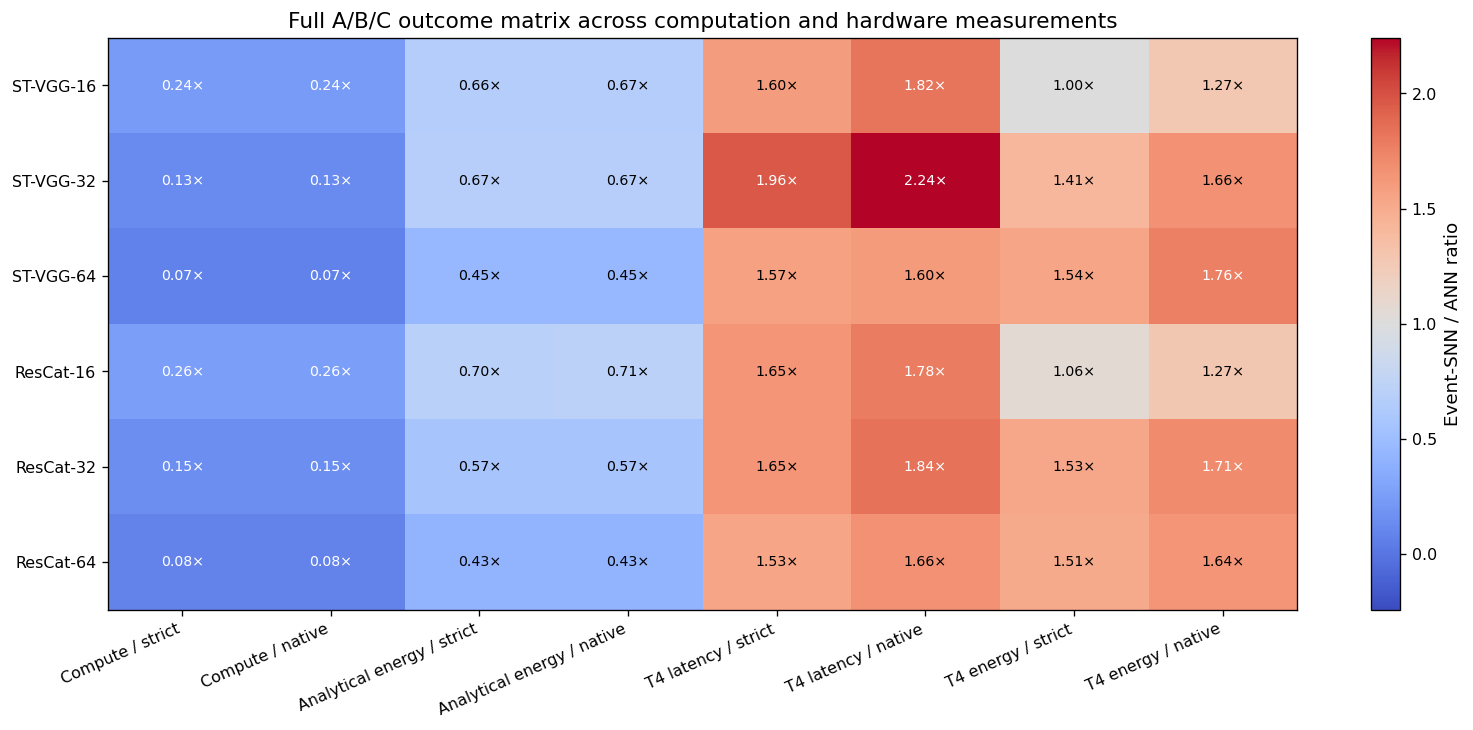

In [124]:
p=ordered_pairs()
# effective compute against ANN-native is computed directly because paired_ABC_ratios.csv stores A/B only for this metric.
eff_native=np.divide(ordered_pipeline('effective_macs_ch6','event_snn'), ordered_pipeline('dense_gmacs','native_ann')*1e9)
cols=[
    ('effective_macs_A_over_B','Compute / strict',None),
    (None,'Compute / native',eff_native),
    ('thesis_energy_A_over_B','Analytical energy / strict',None),
    ('thesis_energy_A_over_C','Analytical energy / native',None),
    ('latency_stream_A_over_B','T4 latency / strict',None),
    ('latency_stream_A_over_C','T4 latency / native',None),
    ('gpu_dynamic_energy_A_over_B','T4 energy / strict',None),
    ('gpu_dynamic_energy_A_over_C','T4 energy / native',None),
]
arrays=[]
for col,label,manual in cols:
    arrays.append(np.asarray(manual,dtype=float) if manual is not None else pd.to_numeric(p[col],errors='coerce').to_numpy(dtype=float))
mat=np.column_stack(arrays)
fig,ax=plt.subplots(figsize=(13.5,6.2))
lim=max(np.nanmax(np.abs(mat-1.0)),0.2)
im=ax.imshow(mat,aspect='auto',interpolation='nearest',vmin=1-lim,vmax=1+lim,cmap='coolwarm')
cb=fig.colorbar(im,ax=ax); cb.set_label('Event-SNN / ANN ratio')
ax.set_yticks(np.arange(6),[VARIANT_LABEL[v] for v in VARIANT_ORDER])
ax.set_xticks(np.arange(len(cols)),[label for _,label,_ in cols],rotation=24,ha='right')
ax.set_title('Full A/B/C outcome matrix across computation and hardware measurements')
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j,i,f'{mat[i,j]:.2f}×',ha='center',va='center',fontsize=8.5,color='black' if abs(mat[i,j]-1)<0.55*lim else 'white')
fig.tight_layout(); save_fig(fig,'fig_17_cross_hardware_ratio_matrix_strict_and_native'); plt.show()
out=pd.DataFrame(mat,columns=[label for _,label,_ in cols]); out.insert(0,'variant',VARIANT_ORDER); out.to_csv(FIG_DIR/'fig_17_cross_hardware_ratio_matrix_source.csv',index=False)


### Figure 18 — Neuromorphic compute–energy–latency scaling of the Event-SNNs

This SNN-only plot combines three quantities from the event-driven/neuromorphic analysis without inventing an ANN SANA-FE baseline:

- x-axis: measured activity-dependent effective synaptic computation;
- y-axis: SANA-FE projected spiking-subgraph energy;
- marker size: SANA-FE projected spiking-subgraph latency.

It shows whether increasing activity-dependent workload is accompanied by higher projected neuromorphic energy and latency across ST-VGG and ResCat scales.


saved: /content/efod_results/thesis_figures/fig_18_sanafe_compute_energy_latency_scaling.png
saved: /content/efod_results/thesis_figures/fig_18_sanafe_compute_energy_latency_scaling.pdf


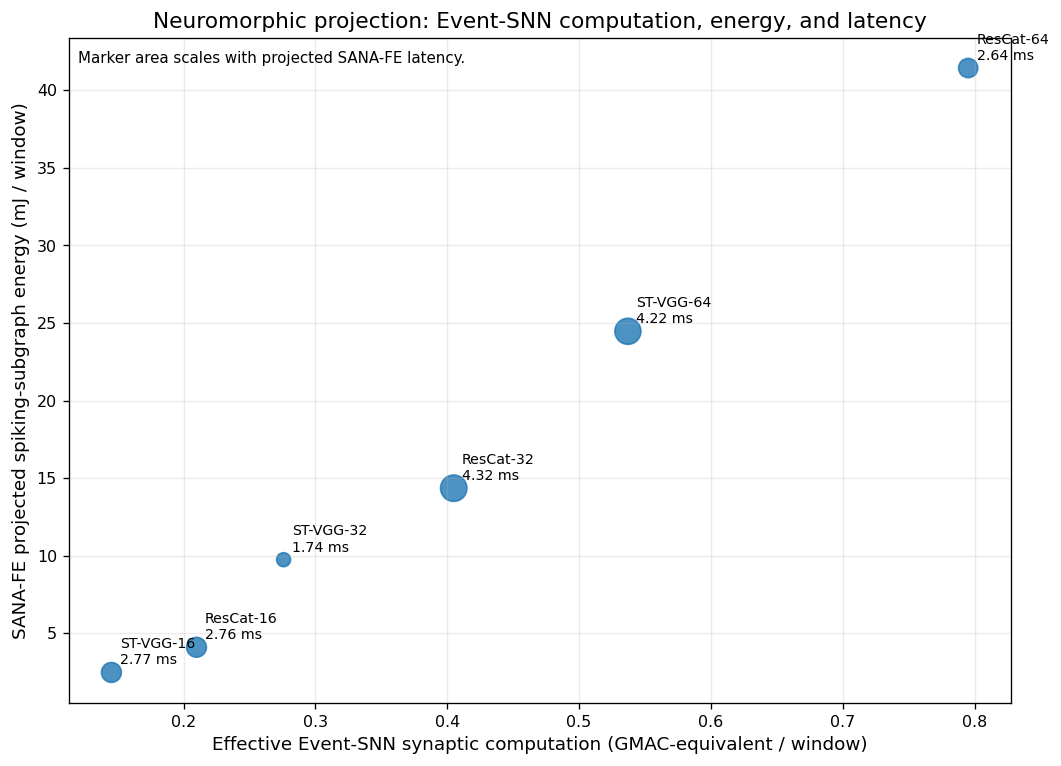

In [122]:
if sana is None:
    print('SANA-FE projection CSV is not available; run the SANA-FE section before this figure.')
else:
    s=sana.copy(); s['variant']=s['variant'].astype(str).str.lower(); s=s.set_index('variant').reindex(VARIANT_ORDER).reset_index()
    x=ordered_pipeline('effective_macs_ch6','event_snn')/1e9
    y=pd.to_numeric(s['sanafe_projected_spiking_subgraph_energy_mJ_per_window'],errors='coerce').to_numpy(dtype=float)
    lat=pd.to_numeric(s['sanafe_projected_spiking_subgraph_latency_ms_per_window'],errors='coerce').to_numpy(dtype=float)
    sizes=70 + 180*(lat-np.nanmin(lat))/max(np.nanmax(lat)-np.nanmin(lat),1e-9)
    fig,ax=plt.subplots(figsize=(9.0,6.5))
    ax.scatter(x,y,s=sizes,alpha=0.8)
    for v,xx,yy,ll in zip(VARIANT_ORDER,x,y,lat):
        ax.annotate(f'{VARIANT_LABEL[v]}\n{ll:.2f} ms',(xx,yy),xytext=(5,5),textcoords='offset points',fontsize=8.5)
    ax.set_xlabel('Effective Event-SNN synaptic computation (GMAC-equivalent / window)')
    ax.set_ylabel('SANA-FE projected spiking-subgraph energy (mJ / window)')
    ax.set_title('Neuromorphic projection: Event-SNN computation, energy, and latency')
    ax.grid(alpha=0.25)
    ax.text(0.01,0.98,'Marker area scales with projected SANA-FE latency.',transform=ax.transAxes,va='top',fontsize=9)
    fig.tight_layout(); save_fig(fig,'fig_18_sanafe_compute_energy_latency_scaling'); plt.show()
    pd.DataFrame({'variant':VARIANT_ORDER,'effective_GMAC':x,'sanafe_energy_mJ':y,'sanafe_latency_ms':lat}).to_csv(FIG_DIR/'fig_18_sanafe_compute_energy_latency_source.csv',index=False)


### Figure export summary

The PNG files are convenient for quick viewing and presentations. For the thesis, prefer the corresponding **PDF vector figures** in LaTeX whenever possible. The source CSV stored beside every figure makes the plots reproducible and keeps the numerical values auditable.


In [125]:
import shutil

files = sorted(FIG_DIR.glob('*'))
print(f'Generated {len(files)} thesis-figure files in {FIG_DIR}:')
for f in files:
    print(' -', f.name)

zip_base='/content/EFOD_thesis_figures'
if FIG_DIR.exists():
    print('Figure package:', shutil.make_archive(zip_base,'zip',str(FIG_DIR)))

# Repackage the complete result tree so the figures are included with the benchmark CSVs.
if RESULTS_DIR.exists():
    print('Updated complete results package:',
          shutil.make_archive('/content/EFOD_trainedSNN_18model_results_with_thesis_figures','zip',str(RESULTS_DIR)))


Generated 55 thesis-figure files in /content/efod_results/thesis_figures:
 - .ipynb_checkpoints
 - fig_01_structural_parity_scope_clean.pdf
 - fig_01_structural_parity_scope_clean.png
 - fig_01_structural_parity_scope_clean_source.csv
 - fig_02_computation_scope_clean.pdf
 - fig_02_computation_scope_clean.png
 - fig_02_computation_scope_clean_source.csv
 - fig_03_layerwise_spike_rate_heatmap.pdf
 - fig_03_layerwise_spike_rate_heatmap.png
 - fig_03_layerwise_spike_rate_source.csv
 - fig_04_gpu_energy_ratios_scope_clean.pdf
 - fig_04_gpu_energy_ratios_scope_clean.png
 - fig_04_gpu_energy_ratios_scope_clean_source.csv
 - fig_05_gpu_dynamic_energy_ci95_scope_clean.pdf
 - fig_05_gpu_dynamic_energy_ci95_scope_clean.png
 - fig_05_gpu_dynamic_energy_ci95_scope_clean_source.csv
 - fig_06_gpu_stream_latency_scope_clean.pdf
 - fig_06_gpu_stream_latency_scope_clean.png
 - fig_06_gpu_stream_latency_scope_clean_source.csv
 - fig_07_memory_parameters_plus_snn_state.pdf
 - fig_07_memory_parameters_plu